# Mapping Narrative Perspective in English and German Creative Writing Manuals: A Preliminary Corpus-Based Exploration

**Subtitle:** An analysis of PsyPer-informed lexical and BM25 retrieval results.

**Audience:** researchers in literary studies, narratology, book studies, creative writing research, and computational literary studies. No specialist knowledge of information retrieval or statistics is assumed.

**Important:** All numerical results below measure **retrieval coverage** (what the dictionary and BM25 systems found), not yet the verified prevalence of narrative-perspective discussion. Human evaluation is still outstanding.


## Reproducibility setup

This notebook loads the frozen candidate corpus snapshot and versioned lexical/BM25 outputs. Heavy tables and figures are produced by `python -m src.analysis.run_np_exploration` and stored under `reports/`. The notebook reloads those artefacts and recomputes only light verification checks so that it remains runnable on modest machines.


In [1]:
import sys
from pathlib import Path as _Path
_ROOT = _Path.cwd()
if not (_ROOT / 'src').is_dir():
    _ROOT = _Path.cwd().parent
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from pathlib import Path
import json
import platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from src.common.paths import ROOT, DATA_PROCESSED, DATA_INTERIM
from src.analysis.narrative_perspective import (
    LANGUAGE_COLORS, LANG_LABEL, SNAPSHOT_ID, source_commit,
    load_corpus_manifest, load_concept_ids, load_retrieval_results,
    reproducibility_record, file_sha256,
)

TABLES = ROOT / 'reports' / 'tables'
FIGURES = ROOT / 'reports' / 'figures' / '01_narrative_perspective'
assert TABLES.is_dir(), 'Run: python -m src.analysis.run_np_exploration'

def show_fig(name, caption):
    png = FIGURES / f'{name}.png'
    display(Image(filename=str(png)))
    display(Markdown(f'*Figure. {caption}*'))

def load_t(name):
    return pd.read_csv(TABLES / f'{name}.csv')

meta_paths = [
    DATA_PROCESSED / 'corpus_manifest_en_v1_candidate.csv',
    DATA_PROCESSED / 'corpus_manifest_de_v1_candidate.csv',
    DATA_PROCESSED / 'pov_baseline_b_v03_lexical_en.csv',
    DATA_PROCESSED / 'pov_baseline_b_v03_lexical_de.csv',
]
run_meta = reproducibility_record(meta_paths)
run_meta['software_versions'].update({
    'python': platform.python_version(),
    'matplotlib': __import__('matplotlib').__version__,
})
display(pd.Series({
    'source_commit': run_meta['source_commit'][:12],
    'corpus_snapshot_id': SNAPSHOT_ID,
    'lexicon_version': run_meta['lexicon_version'],
    'retrieval_baseline_version': run_meta['retrieval_baseline_version'],
    'execution_timestamp': run_meta['execution_timestamp'],
}).to_frame('value'))


,value
source_commit,912981babb36
corpus_snapshot_id,corpus_snapshot_analysis_v1_candidate_20261122
lexicon_version,0.3-draft
retrieval_baseline_version,v0.3
execution_timestamp,2026-11-22T19:30:06.717173+00:00


## 1. Introduction and research motivation

Creative writing manuals are valuable sources for investigating how narrative perspective is **conceptualized, taught and operationalized** in writing practice across linguistic and literary traditions.

Examining manuals may reveal differences in:
- theoretical terminology,
- practical writing recommendations,
- narrative techniques,
- cognitive and emotional understandings of perspective,
- the relationship between academic narratology and creative writing pedagogy.

**Connection to PsyPer.** The retrieval lexicon is *informed by* PsyPer-related annotation interests. An annotation scheme originally intended for narratives cannot automatically classify theoretical discussions in writing manuals. Not all 36 retrieval concepts are official PsyPer categories (see `docs/psyper_vs_retrieval_concepts_v05.md`).

**Research questions (exploratory):**
1. Which aspects of narrative perspective are identified in EN/DE manuals?
2. How do distributions differ between the two language corpora?
3. How do they vary by manual type?
4. Which aspects tend to be discussed together?
5. To what extent do lexical retrieval and BM25 identify complementary material?
6. How sensitive are findings to vocabulary coverage, corpus composition and data-quality decisions?


## 2. Corpus overview

**Research question:** How large are the English and German corpora, and how are they structured?

**Why useful:** Absolute counts cannot be compared across languages of different size without denominators.

**Data:** versioned corpus manifests (`corpus_manifest_{en,de}_v1_candidate.csv`).


,language,listed_books,analysis_set_books,excluded_books,n_authors,words,eligible_paragraphs
0,English,503,442,61,408,34581264,315302
1,German,78,67,11,56,4665385,42623


**Verification from manifests (must match overview table):**

,language,listed,analysis,words,paras
0,English,503,442,34581264,315302
1,German,78,67,4665385,42623


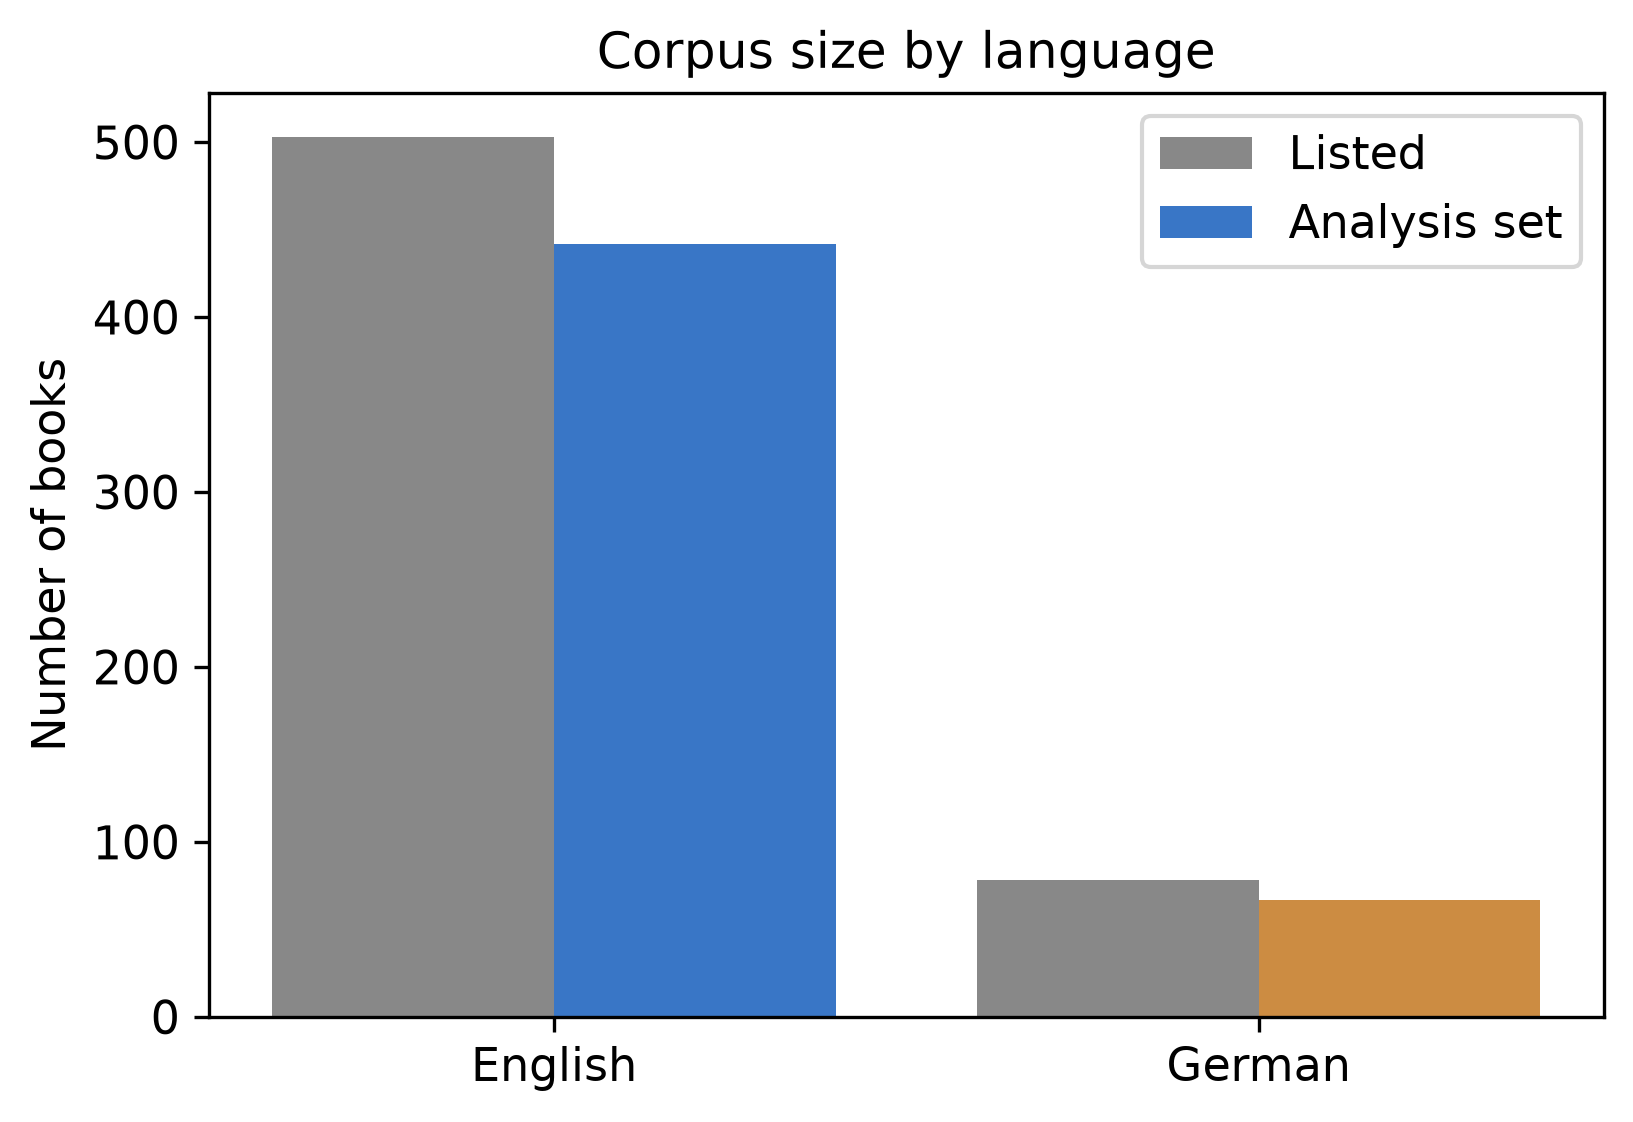

*Figure. Listed versus analysis-set books by language.*

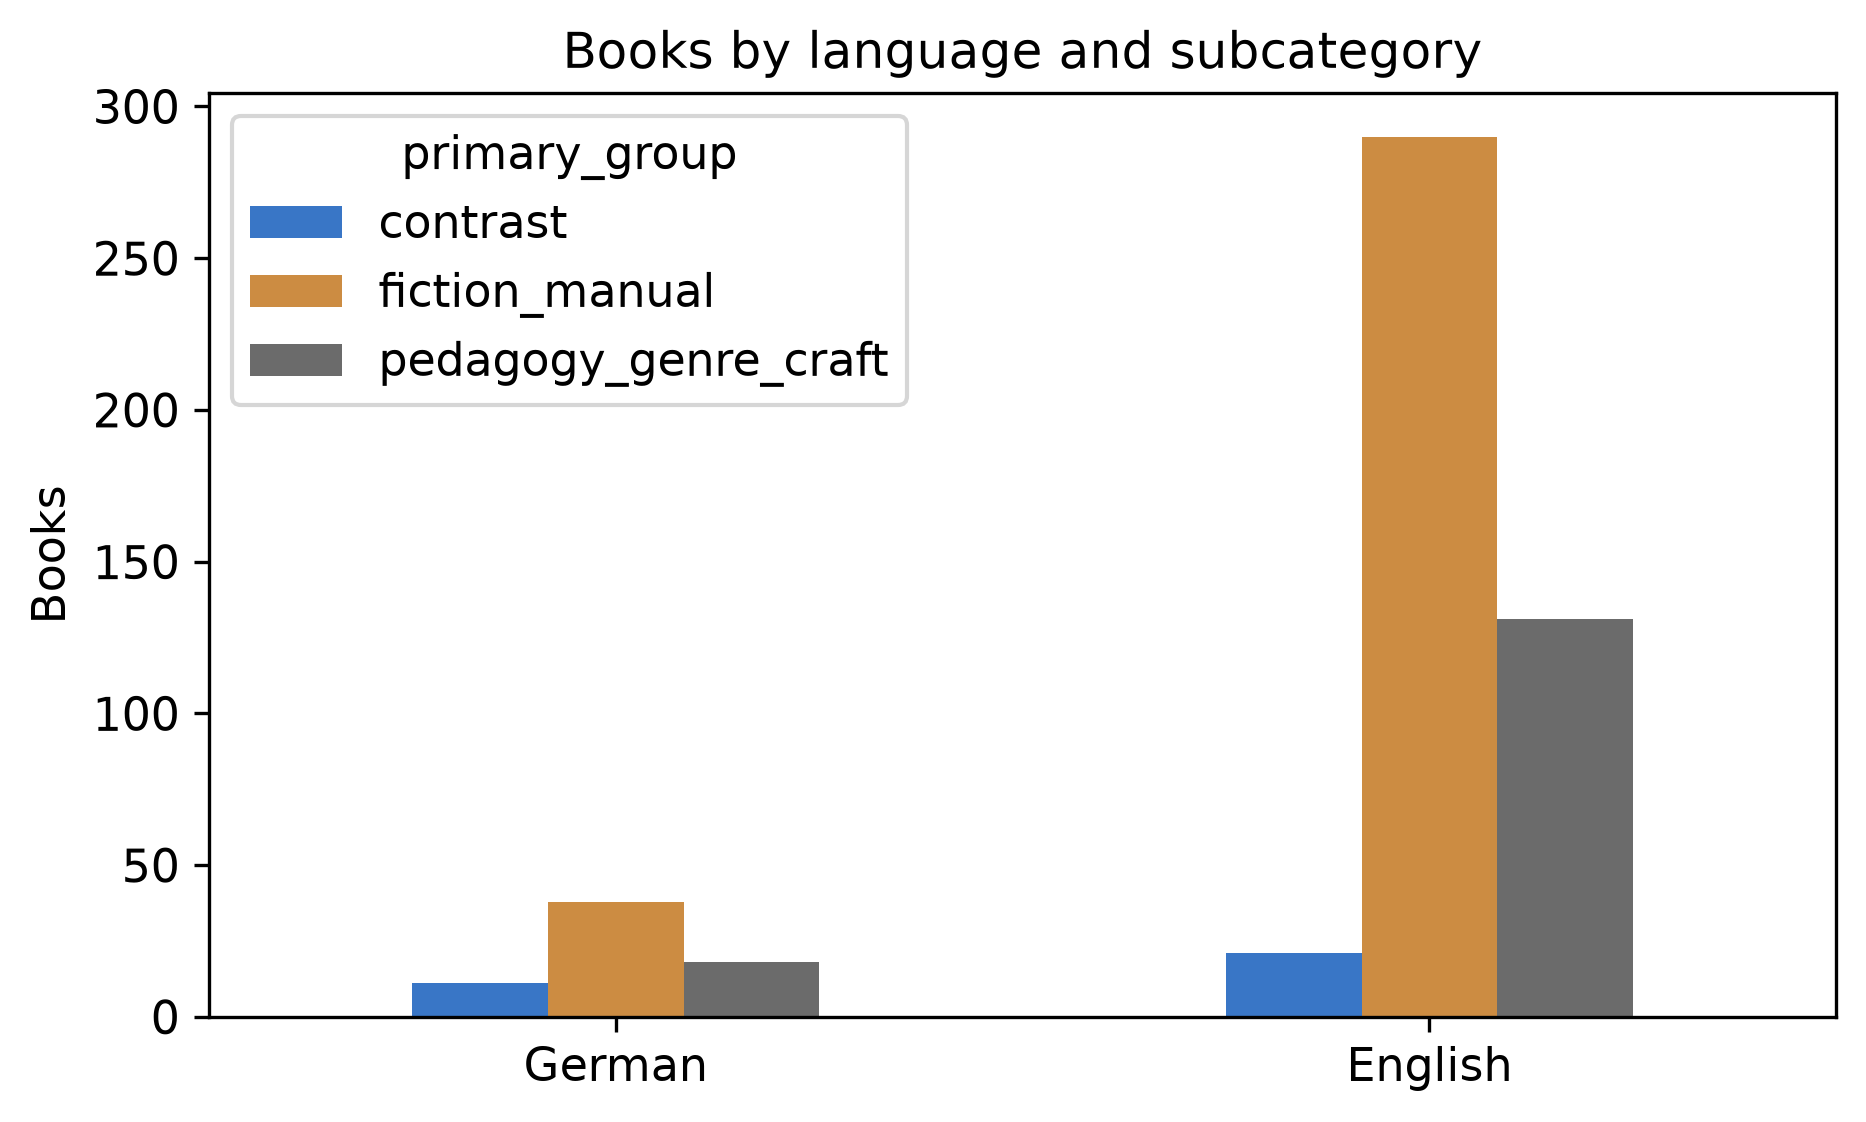

*Figure. Books by language and primary_group.*

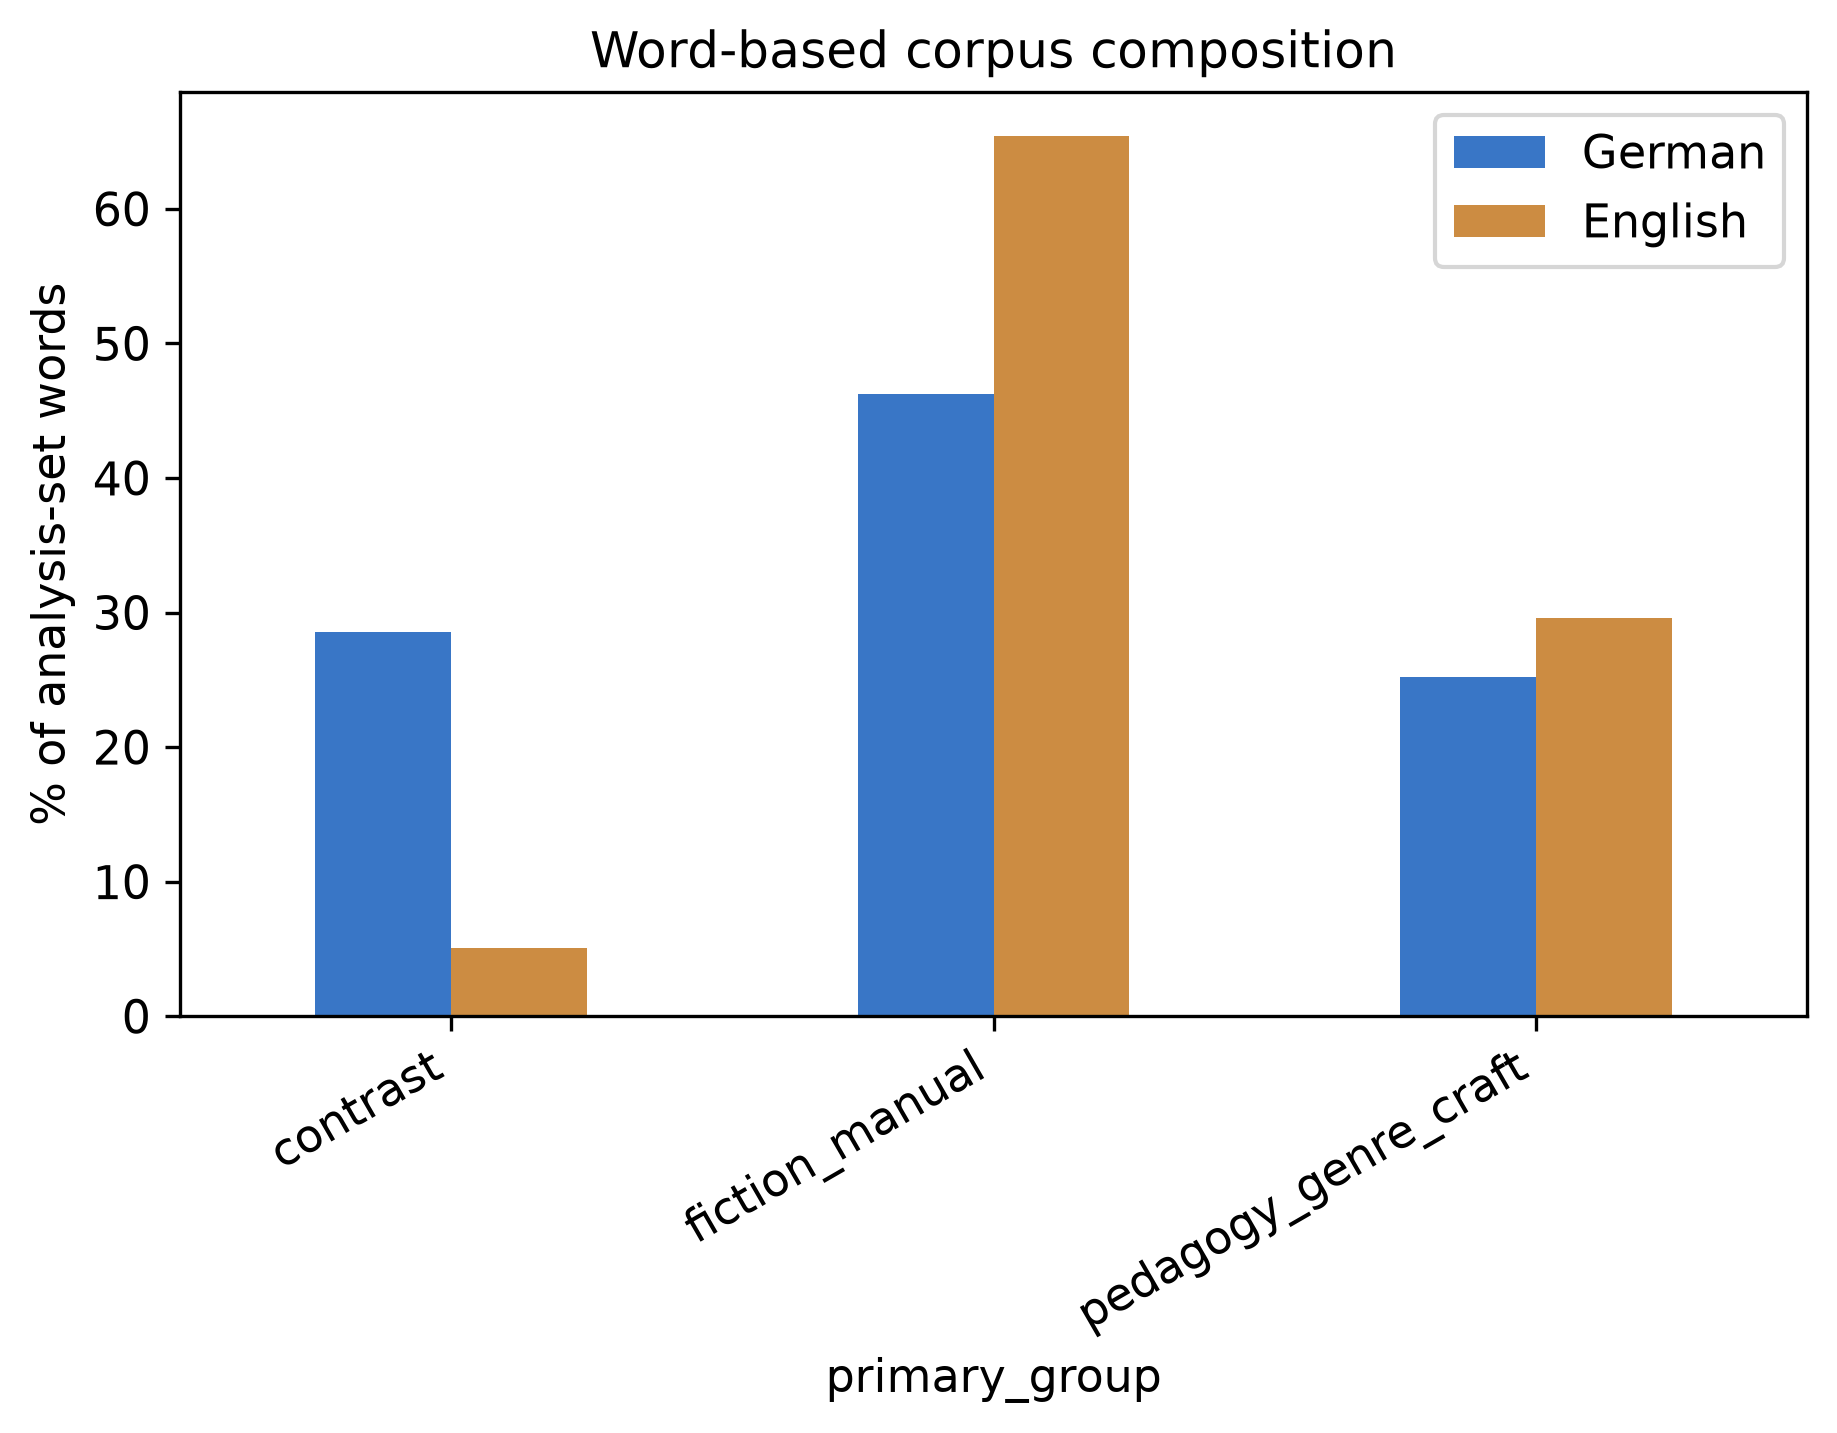

*Figure. Share of analysis-set words by corpus category.*

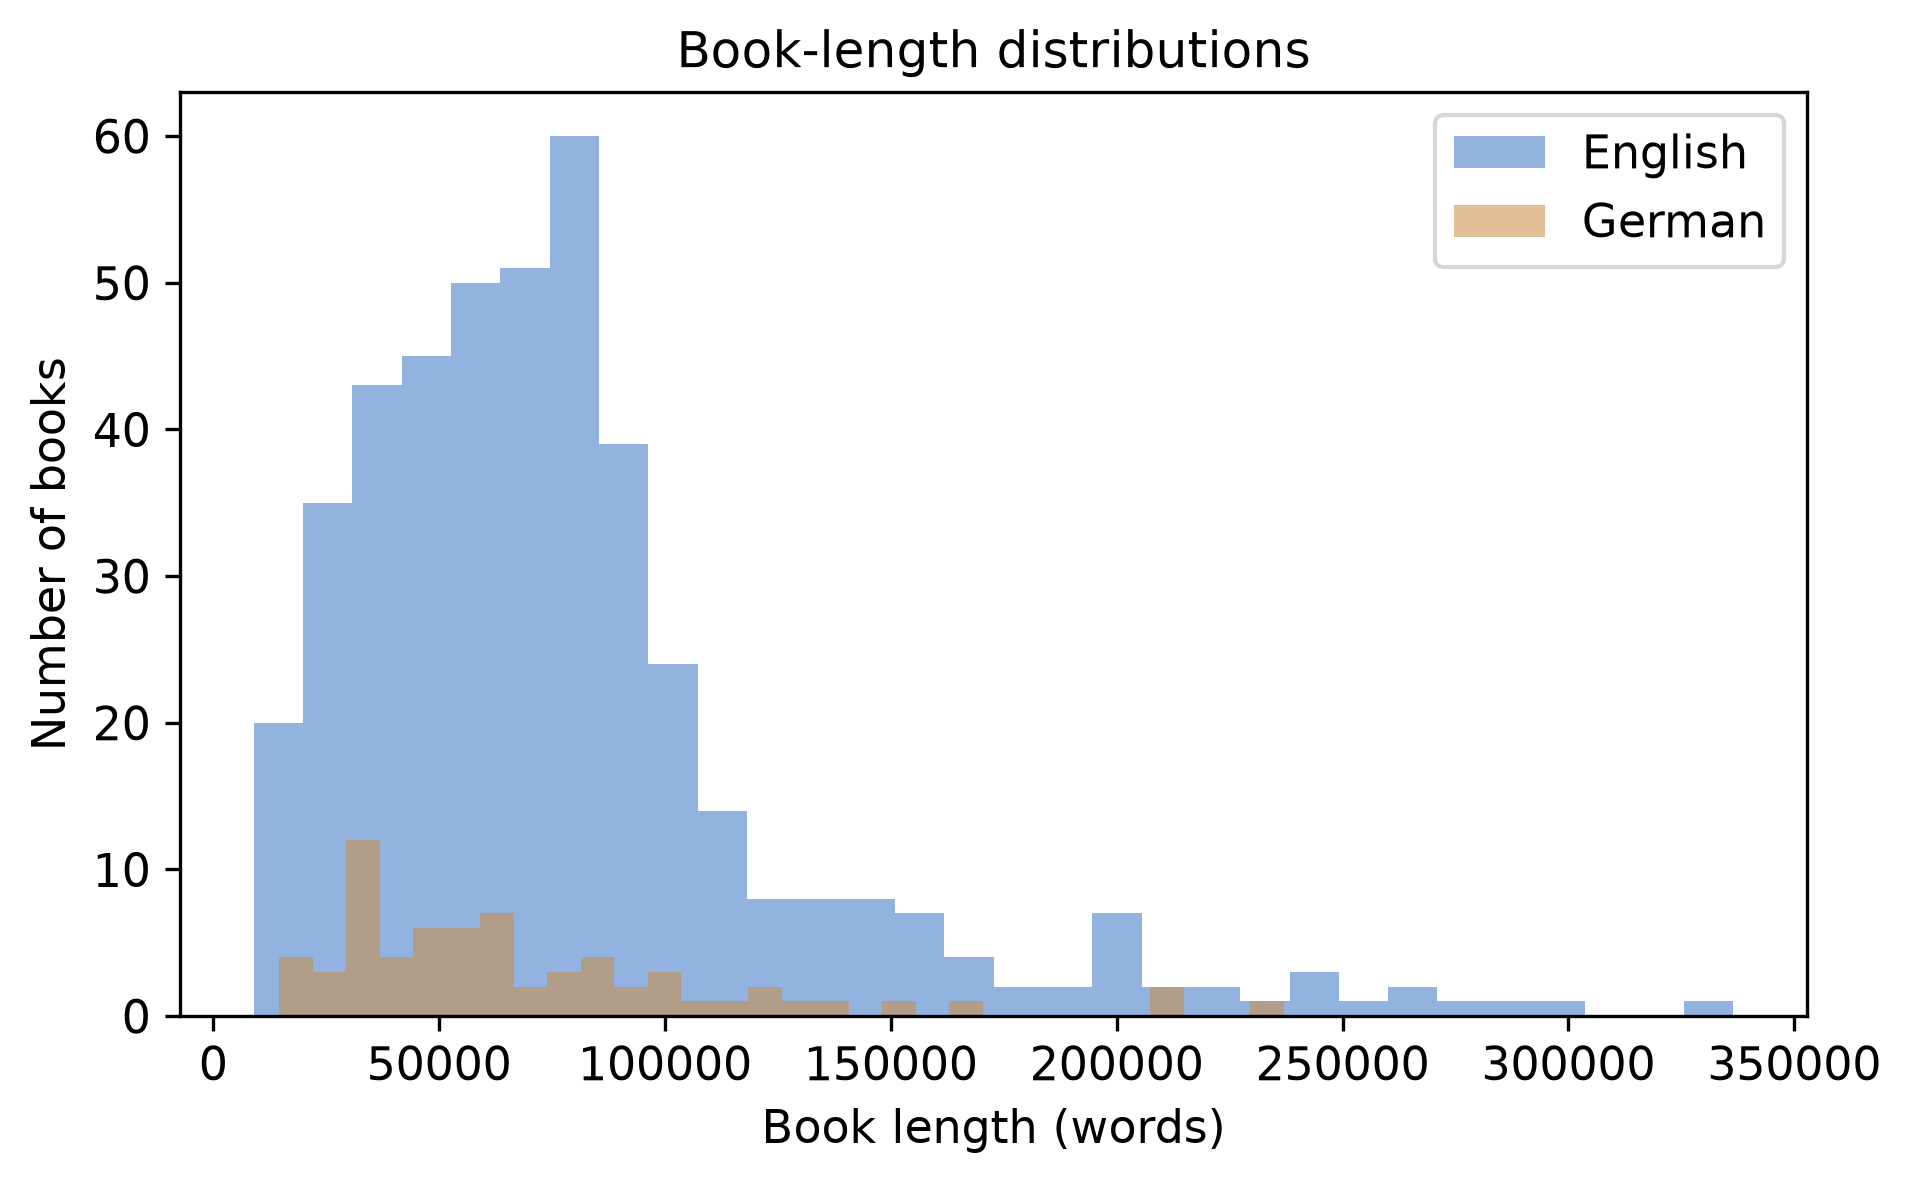

*Figure. Distribution of book lengths (words).*

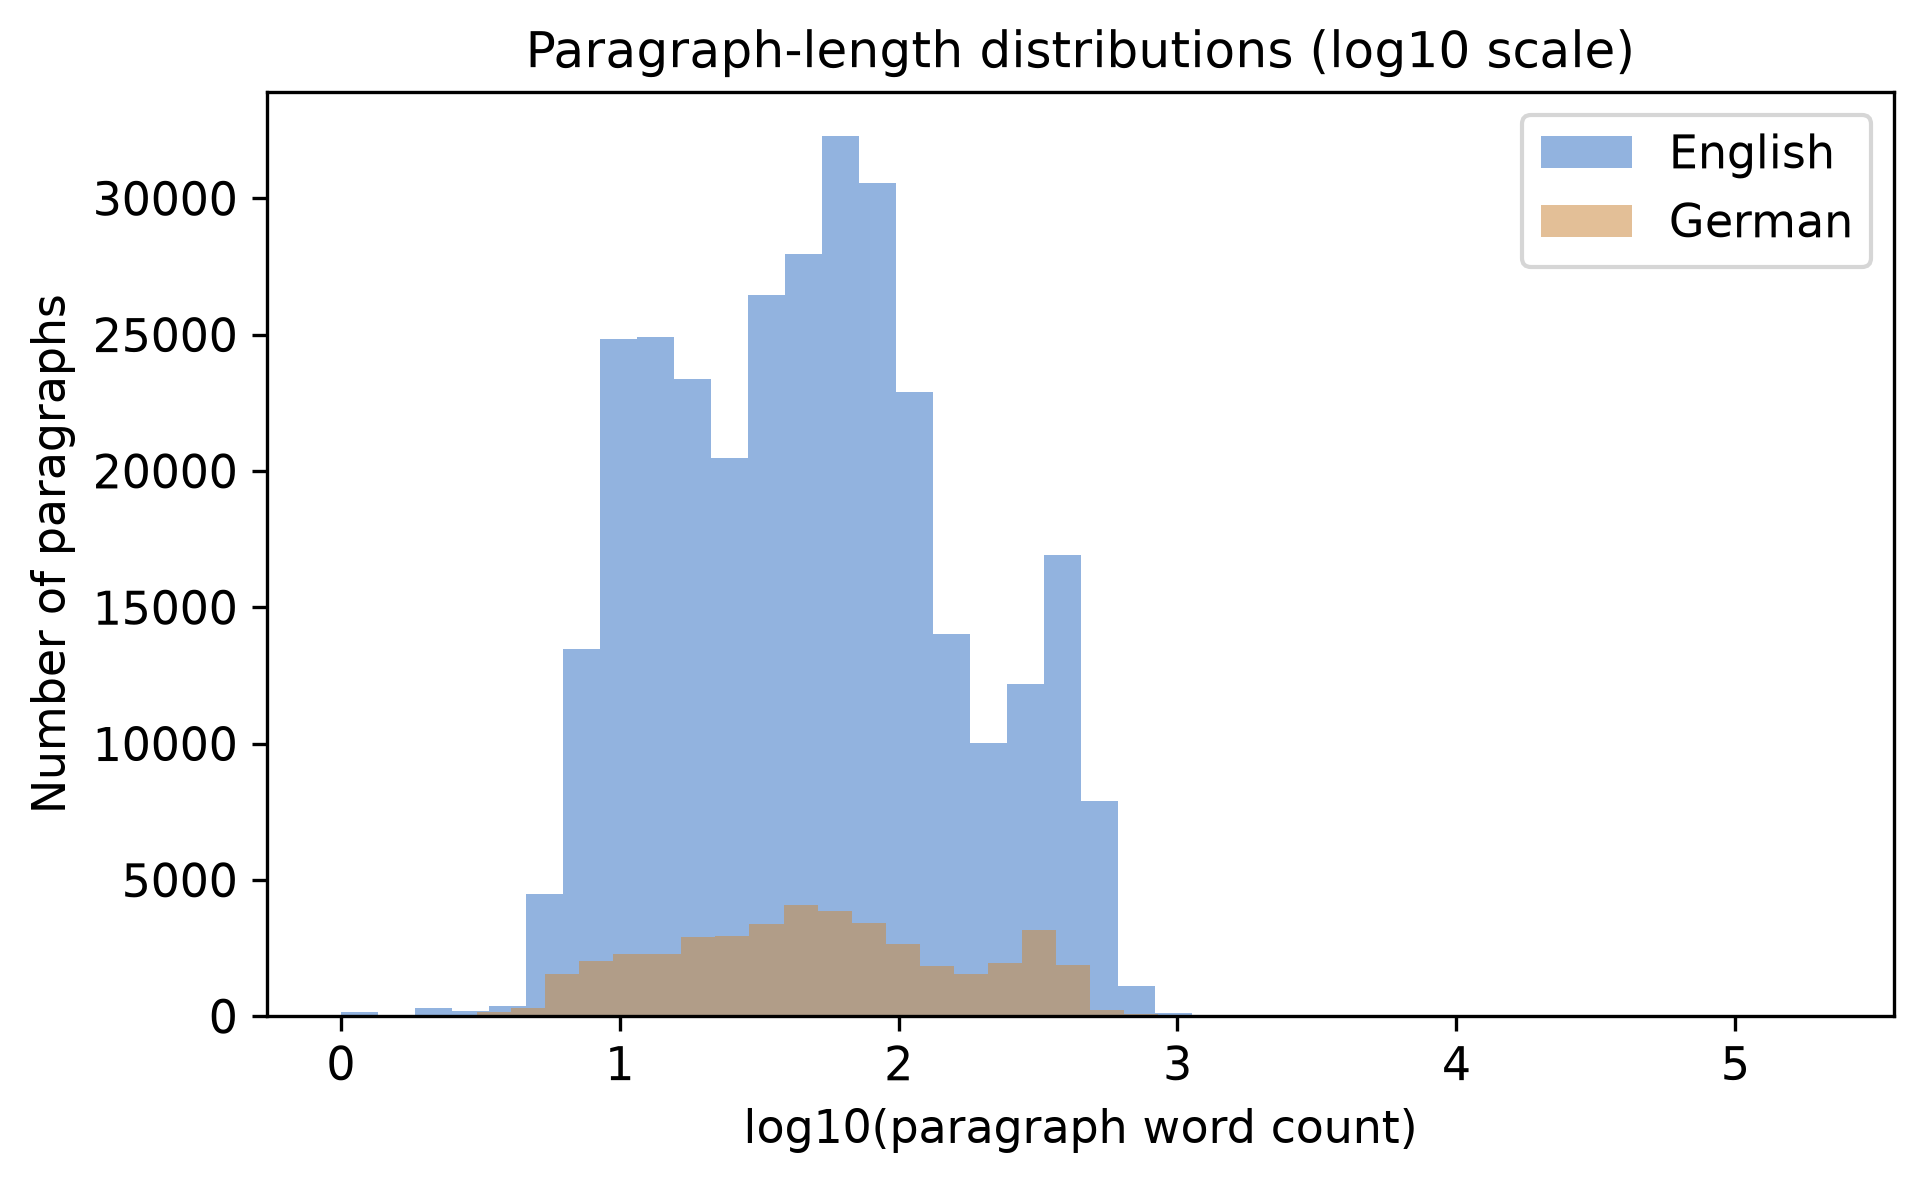

*Figure. Paragraph lengths on a log10 scale.*

In [2]:
overview = load_t('corpus_overview')
display(overview)
# Verify dynamically from manifests (not hardcoded).
corpus = load_corpus_manifest()
a = corpus[corpus['in_analysis_set'].astype(str).str.lower().isin(('true','1'))].copy()
a['number_of_words'] = pd.to_numeric(a['number_of_words'], errors='coerce').fillna(0)
a['number_of_eligible_paragraphs'] = pd.to_numeric(a['number_of_eligible_paragraphs'], errors='coerce').fillna(0)
check = []
for lang, label in LANG_LABEL.items():
    cl = corpus[corpus.language==lang]
    al = a[a.language==lang]
    check.append({
        'language': label,
        'listed': len(cl),
        'analysis': len(al),
        'words': int(al.number_of_words.sum()),
        'paras': int(al.number_of_eligible_paragraphs.sum()),
    })
check_df = pd.DataFrame(check)
display(Markdown('**Verification from manifests (must match overview table):**'))
display(check_df)
show_fig('01_corpus_size', 'Listed versus analysis-set books by language.')
show_fig('02_books_by_subcategory', 'Books by language and primary_group.')
show_fig('03_word_composition', 'Share of analysis-set words by corpus category.')
show_fig('04_book_length', 'Distribution of book lengths (words).')
show_fig('05_paragraph_length_log', 'Paragraph lengths on a log10 scale.')


### How to read these figures

- **Corpus size** distinguishes catalogue listings from the analysis set (books with usable full text that pass inclusion rules).
- **Word composition** shows that the German corpus has a much larger share of *contrast* materials (narratology / academic writing about writing).
- **Paragraph length (log scale)** is used because paragraph lengths are highly skewed; a linear axis would hide the bulk of short paragraphs behind a few extreme values.

**What the results suggest:** English analysis-set texts are roughly 7× larger in words than German. Absolute hit counts will therefore look larger in English even when rates are similar.

**What cannot yet be concluded:** That English manuals “discuss perspective more” — we have not yet validated retrieval precision/recall.


## 3. Corpus composition and comparability

**Research question:** Do language differences partly reflect unequal corpus composition?

We recompute word shares and later repeat analyses on (1) the full analysis set, (2) primary creative-writing materials excluding contrast, and (3) separate categories.


In [3]:
comp = load_t('corpus_composition_by_group')
piv = comp.pivot(index='primary_group', columns='language', values='pct_words')
piv.columns = [LANG_LABEL[c] for c in piv.columns]
display(piv.round(1))
display(Markdown(
    'German contrast materials contribute substantially more to total words '
    f"({piv.loc['contrast','German']:.1f}% vs {piv.loc['contrast','English']:.1f}%). "
    'A full-corpus difference may therefore reflect composition rather than language.'
))


,German,English
primary_group,,
contrast,28.6,5.0
fiction_manual,46.2,65.4
pedagogy_genre_craft,25.2,29.6


German contrast materials contribute substantially more to total words (28.6% vs 5.0%). A full-corpus difference may therefore reflect composition rather than language.

## 4. Data quality and limitations

**Research question:** Which metadata and segmentation issues constrain interpretation?


,0,1
corpus_snapshot_id,corpus_snapshot_analysis_v1_candidate_20261122,corpus_snapshot_analysis_v1_candidate_20261122
language,en,de
n_listed_books,503,78
n_analysis_set_books,442,67
n_excluded_books,61,11
n_missing_or_unreadable_fulltext,0,0
n_eligible_passages,315302,42623
n_extreme_length_passages,49,7
n_duplicate_passage_ids,0,0
pct_analysis_books_missing_publication_year,28.28,62.69


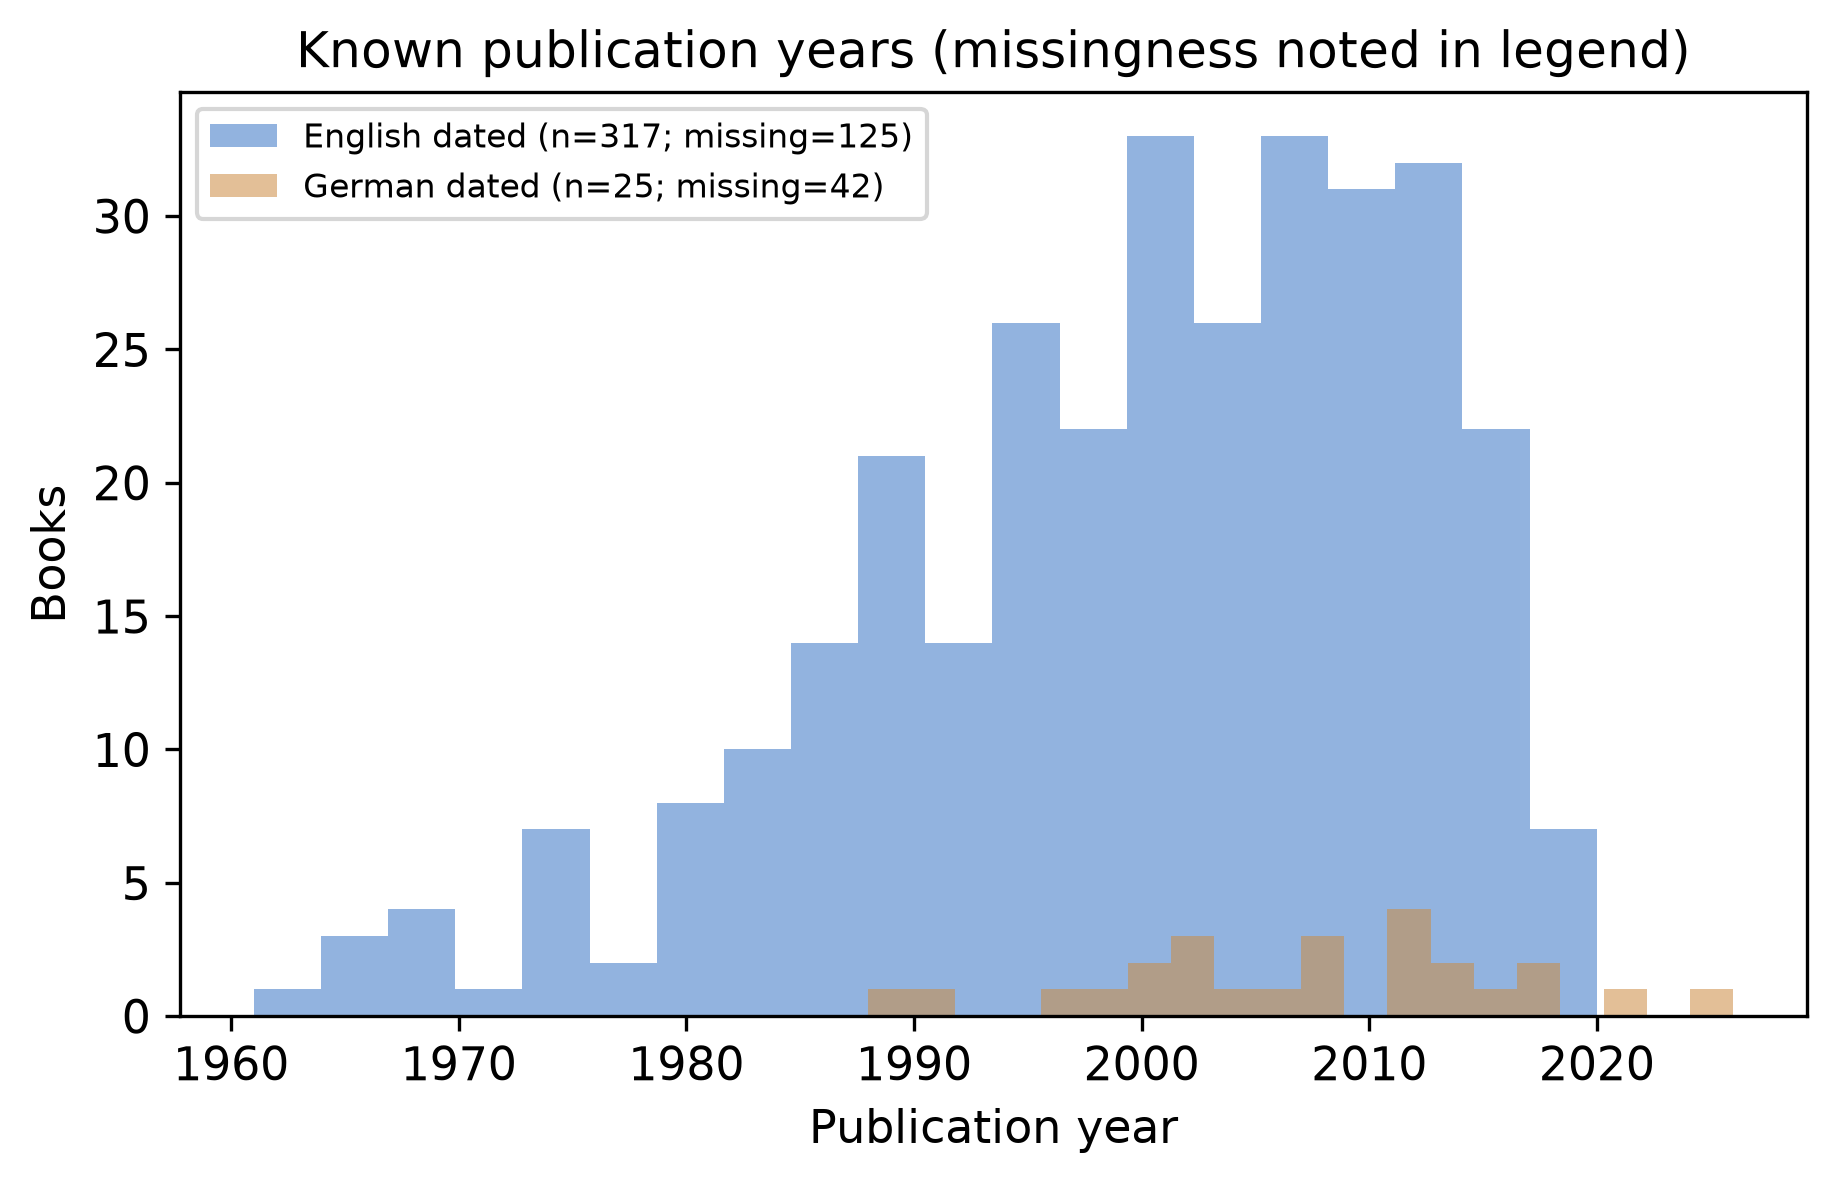

*Figure. Known publication years; missingness is listed in the legend.*

Missing publication years: roughly **28%** of English and **63%** of German analysis-set books. A detailed historical comparison is currently premature. `work_id` is missing for most books (~94%); we cannot safely assume each book_id is a unique work. Extreme-length paragraphs (EN 49 / DE 7) remain in the frozen snapshot and are flagged, not silently removed.

In [4]:
qc = load_t('corpus_quality')
display(qc.T)
show_fig('06_publication_years', 'Known publication years; missingness is listed in the legend.')
display(Markdown(
    'Missing publication years: roughly **28%** of English and **63%** of German analysis-set books. '
    'A detailed historical comparison is currently premature. '
    '`work_id` is missing for most books (~94%); we cannot safely assume each book_id is a unique work. '
    'Extreme-length paragraphs (EN 49 / DE 7) remain in the frozen snapshot and are flagged, not silently removed.'
))


## 5. Retrieval methodology (accessible summary)

### Dictionary-based (lexical) retrieval
The multilingual dictionary contains academic expressions, practical writing terminology, paraphrases, supporting contextual expressions, and morphological/orthographic variants. **Evidence tiers** decide whether a candidate is accepted (e.g. context cues alone are not enough).

### Regular expressions
Regexes identify related word forms (e.g. German *allwissen\**). Broad patterns raise recall but can generate false positives outside craft instruction.

### BM25
BM25 ranks paragraphs by estimated lexical relevance to a concept query, accounting for term frequency, rarity across the collection, document length, and diminishing returns from repeated terms. It can surface passages that exact phrase matching misses.

We distinguish:
- **L** — lexical assignments
- **Bq** — lexical-qualified BM25 (top-K = 500)
- **Braw** — independent exploratory BM25 heap (top-K = 100; historical raw heap not fully on disk)
- **Bnew** — genuinely new exploratory assignments (≈ on-disk BM25-only file)
- **B_combined** — reconstructed Bq ∪ Bnew file (**not** an independent top-K ranking)
- **U** — L ∪ exploratory pool

### Units of analysis
- one **retrieved passage**
- one **passage–concept assignment** (a passage with four concepts contributes four assignments)
- one **book**

Using the wrong denominator changes the meaning of every rate.


## 6. Overall retrieval coverage

**Measure:** normalized frequency = (matches / words) × 10,000.

**Interpretation:** this is retrieval coverage, not verified conceptual prevalence.


In [5]:
cov = load_t('retrieval_coverage')
display(cov.round(3))
# Worked example from actual English data
row = cov[cov.language=='English'].iloc[0]
ex = (row.assignments / (overview.loc[overview.language=='English','words'].iloc[0]) * 10000)
display(Markdown(
    f"**Worked example (English assignments):** "
    f"{int(row.assignments):,} assignments / {int(overview.loc[overview.language=='English','words'].iloc[0]):,} words "
    f"× 10,000 = **{ex:.3f}** assignments per 10,000 words."
))
display(Markdown(
    'English and German passage rates per 10,000 words are similar (~2.0), '
    'while absolute assignment counts differ mainly because of corpus size.'
))


,language,retrieved_passages,assignments,pct_eligible_paragraphs,passages_per_10k_words,assignments_per_10k_words,avg_concepts_per_retrieved_passage,concepts_nonzero
0,English,7380,10643,2.341,2.134,3.078,1.442,36
1,German,941,1380,2.208,2.017,2.958,1.467,32


**Worked example (English assignments):** 10,643 assignments / 34,581,264 words × 10,000 = **3.078** assignments per 10,000 words.

English and German passage rates per 10,000 words are similar (~2.0), while absolute assignment counts differ mainly because of corpus size.

## 7. Changes across lexical baseline versions

Comparing lexical v0.2 → algorithmic corrections → v0.3. An increase in candidates is **not** sufficient evidence of improved recall.


,language,n_v02,n_algo_fix,n_v03,preserved_v02_to_v03,added_v02_to_v03,removed_v02_to_v03,gained_algo_fix,gained_vocab_after_fix
0,English,10611,10630,10643,10611,32,0,19,13
1,German,1034,1050,1380,1034,346,0,16,330


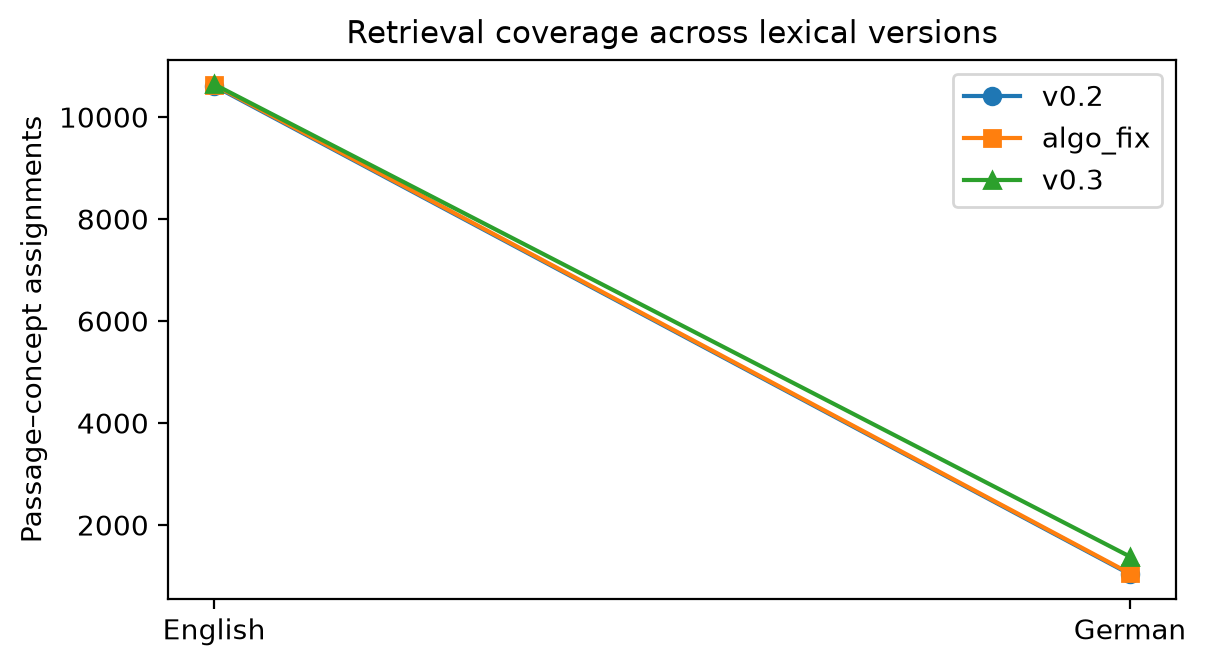

*Figure. Assignment counts across lexical versions by language.*

German gains are largely vocabulary/regex expansions (e.g. focalization_zero, stance_narratorial, stance_figural, grammatical_third_person). Algorithmic fixes contribute only small increments. More candidates can also mean more false positives.

In [6]:
vd = load_t('version_deltas')
display(vd)
show_fig('15_version_coverage', 'Assignment counts across lexical versions by language.')
display(Markdown(
    'German gains are largely vocabulary/regex expansions (e.g. focalization_zero, stance_narratorial, '
    'stance_figural, grammatical_third_person). Algorithmic fixes contribute only small increments. '
    'More candidates can also mean more false positives.'
))


## 8. Frequency profiles of all 36 concepts

All configured concepts are listed, including zeros. Zero retrieval ≠ proven absence from the corpus.


,concept_id,concept_family,language_label,n_assignments,n_unique_passages,n_books,frequency_per_10000_words,frequency_per_1000_paragraphs,percentage_of_books,median_book_frequency
2,grammatical_first_person,perspective_and_person,English,2510,2510,328,0.725827,7.960622,74.208145,0.31637
4,grammatical_third_person,perspective_and_person,English,2031,2031,292,0.587312,6.441443,66.063348,0.24017
0,perspective_general,perspective_and_person,English,1267,1267,144,0.366383,4.018370,32.579186,0.00000
13,focalization_zero,focalization,English,1016,1016,199,0.293801,3.222308,45.022624,0.00000
3,grammatical_second_person,perspective_and_person,English,552,552,170,0.159624,1.750703,38.461538,0.00000
20,mode_narrative,mode_of_presentation,English,492,492,122,0.142274,1.560409,27.601810,0.00000
1,voice_general,perspective_and_person,English,438,438,121,0.126658,1.389144,27.375566,0.00000
24,thought_representation,consciousness_and_techniques,English,377,377,89,0.109019,1.195679,20.135747,0.00000
34,narrative_style_voice,consciousness_and_techniques,English,235,235,113,0.067956,0.745317,25.565611,0.00000
23,consciousness_access,consciousness_and_techniques,English,212,212,98,0.061305,0.672371,22.171946,0.00000


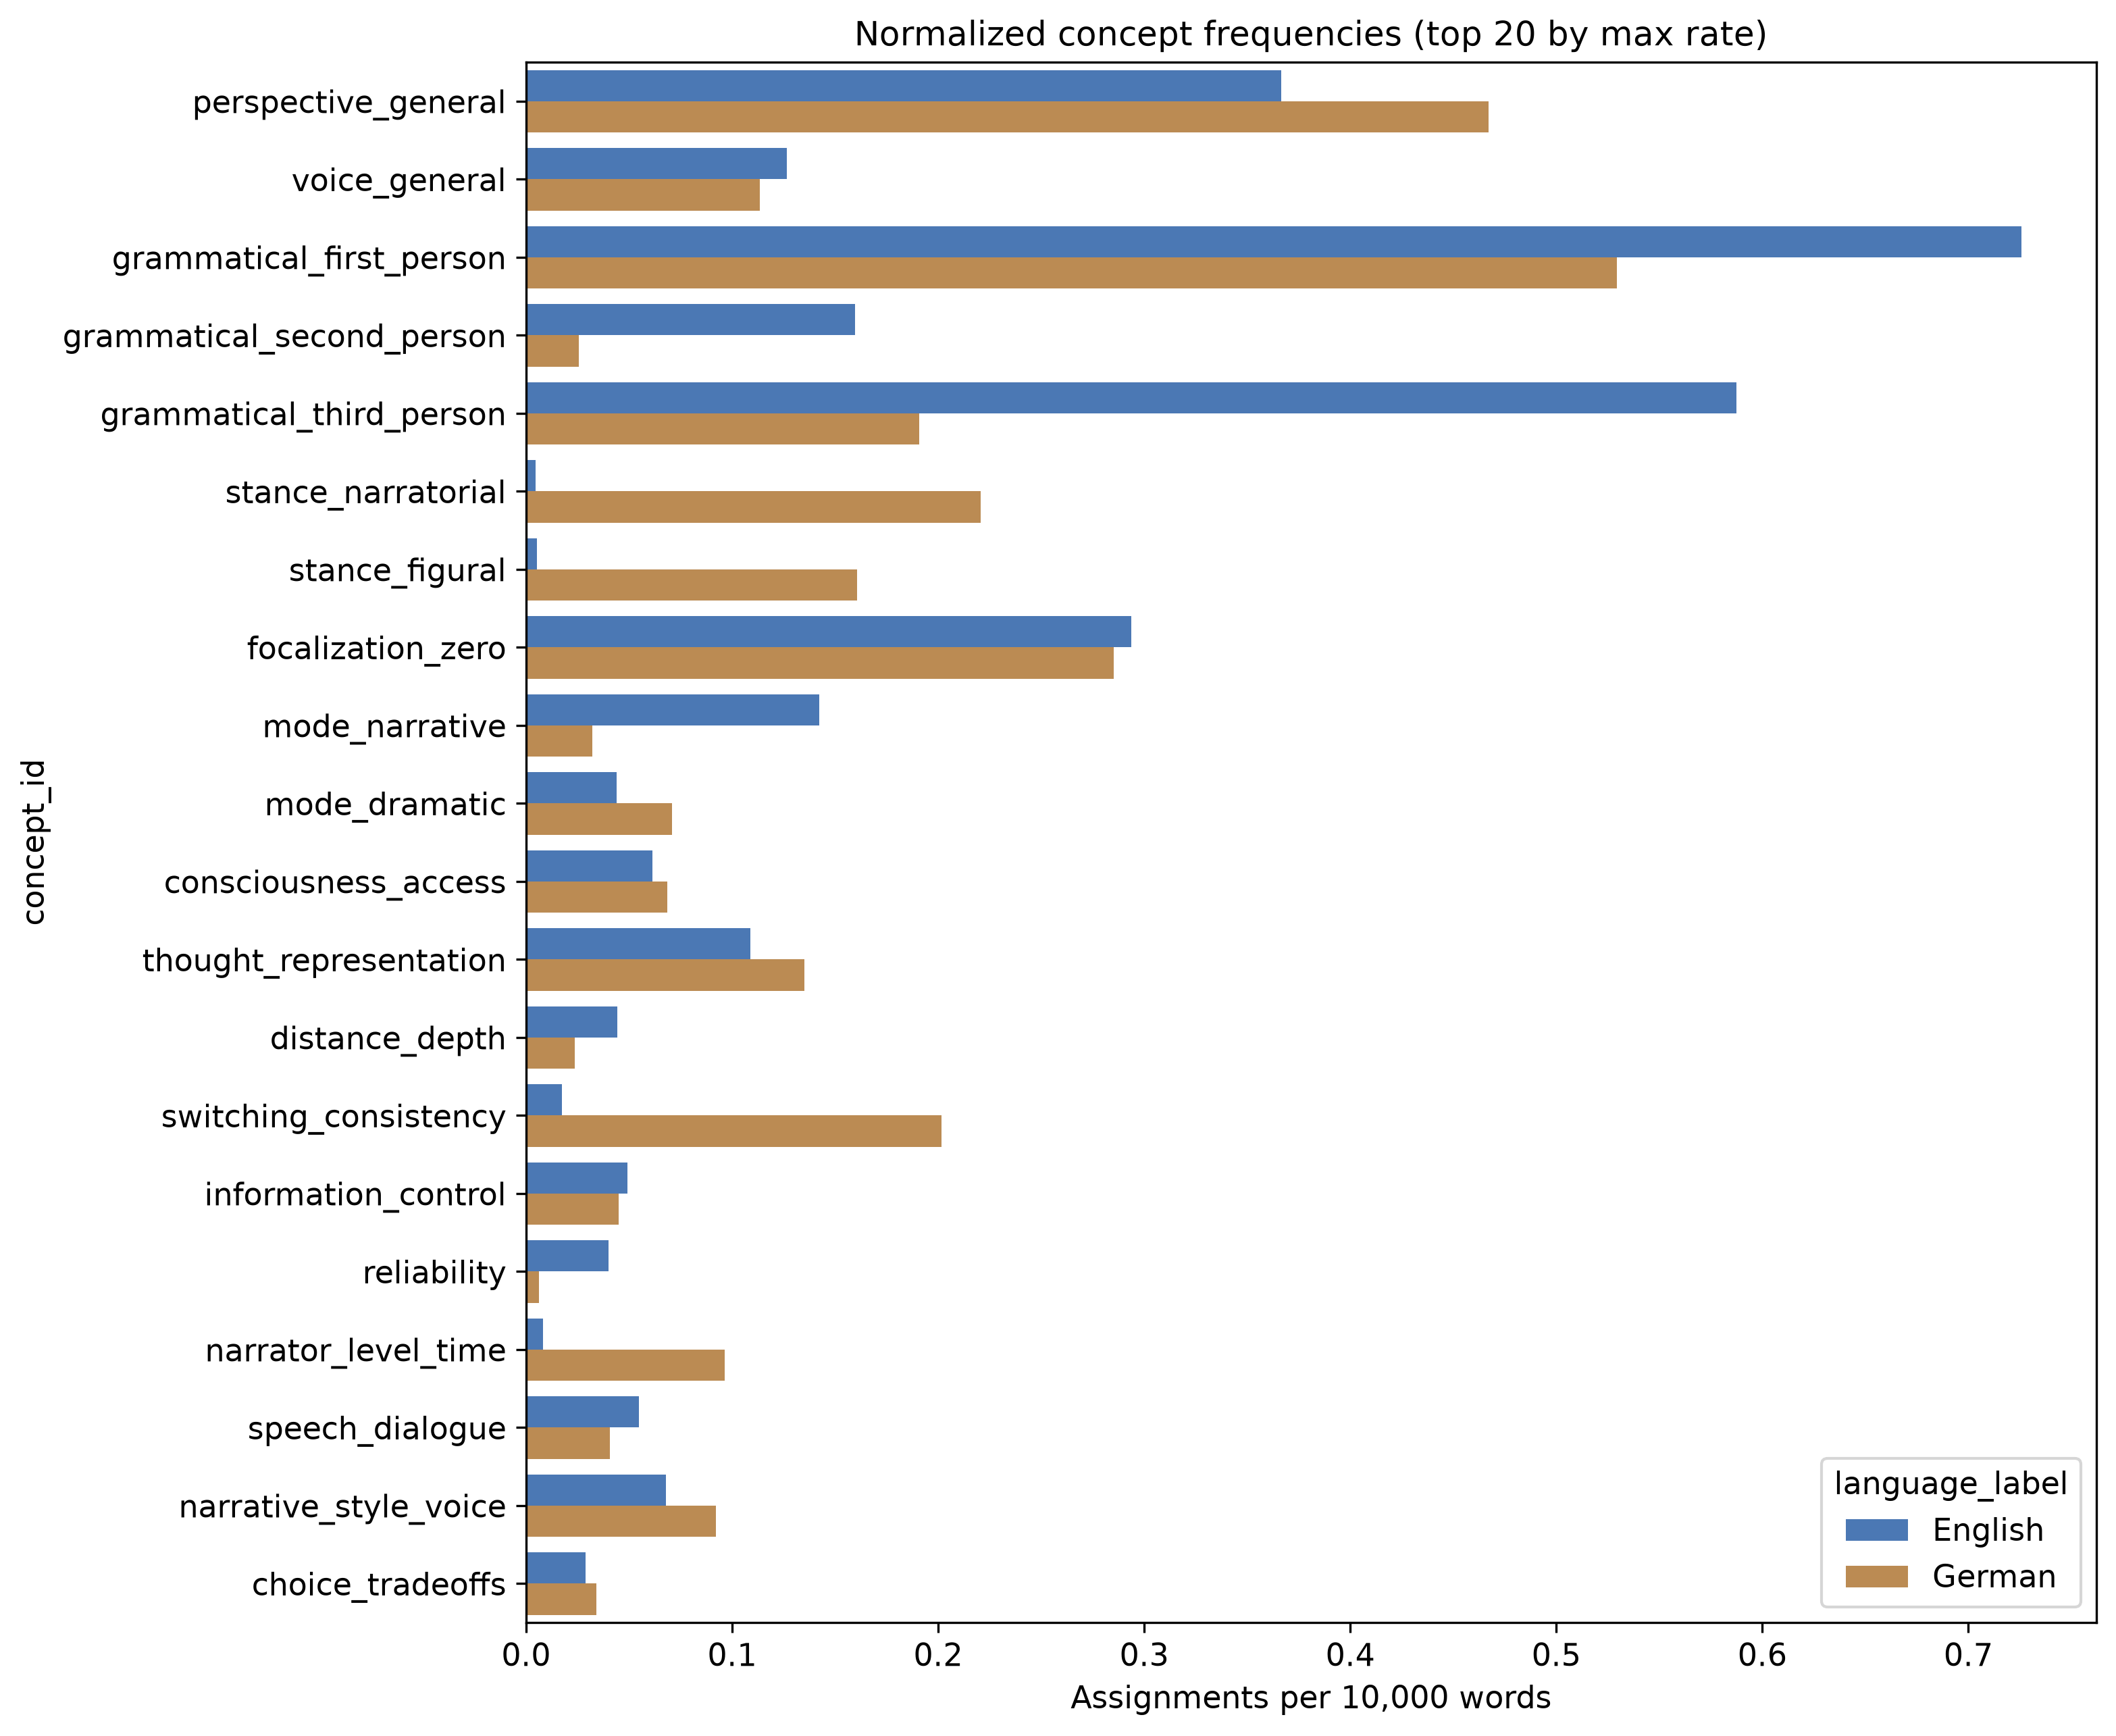

*Figure. Top 20 concepts by maximum normalized frequency.*

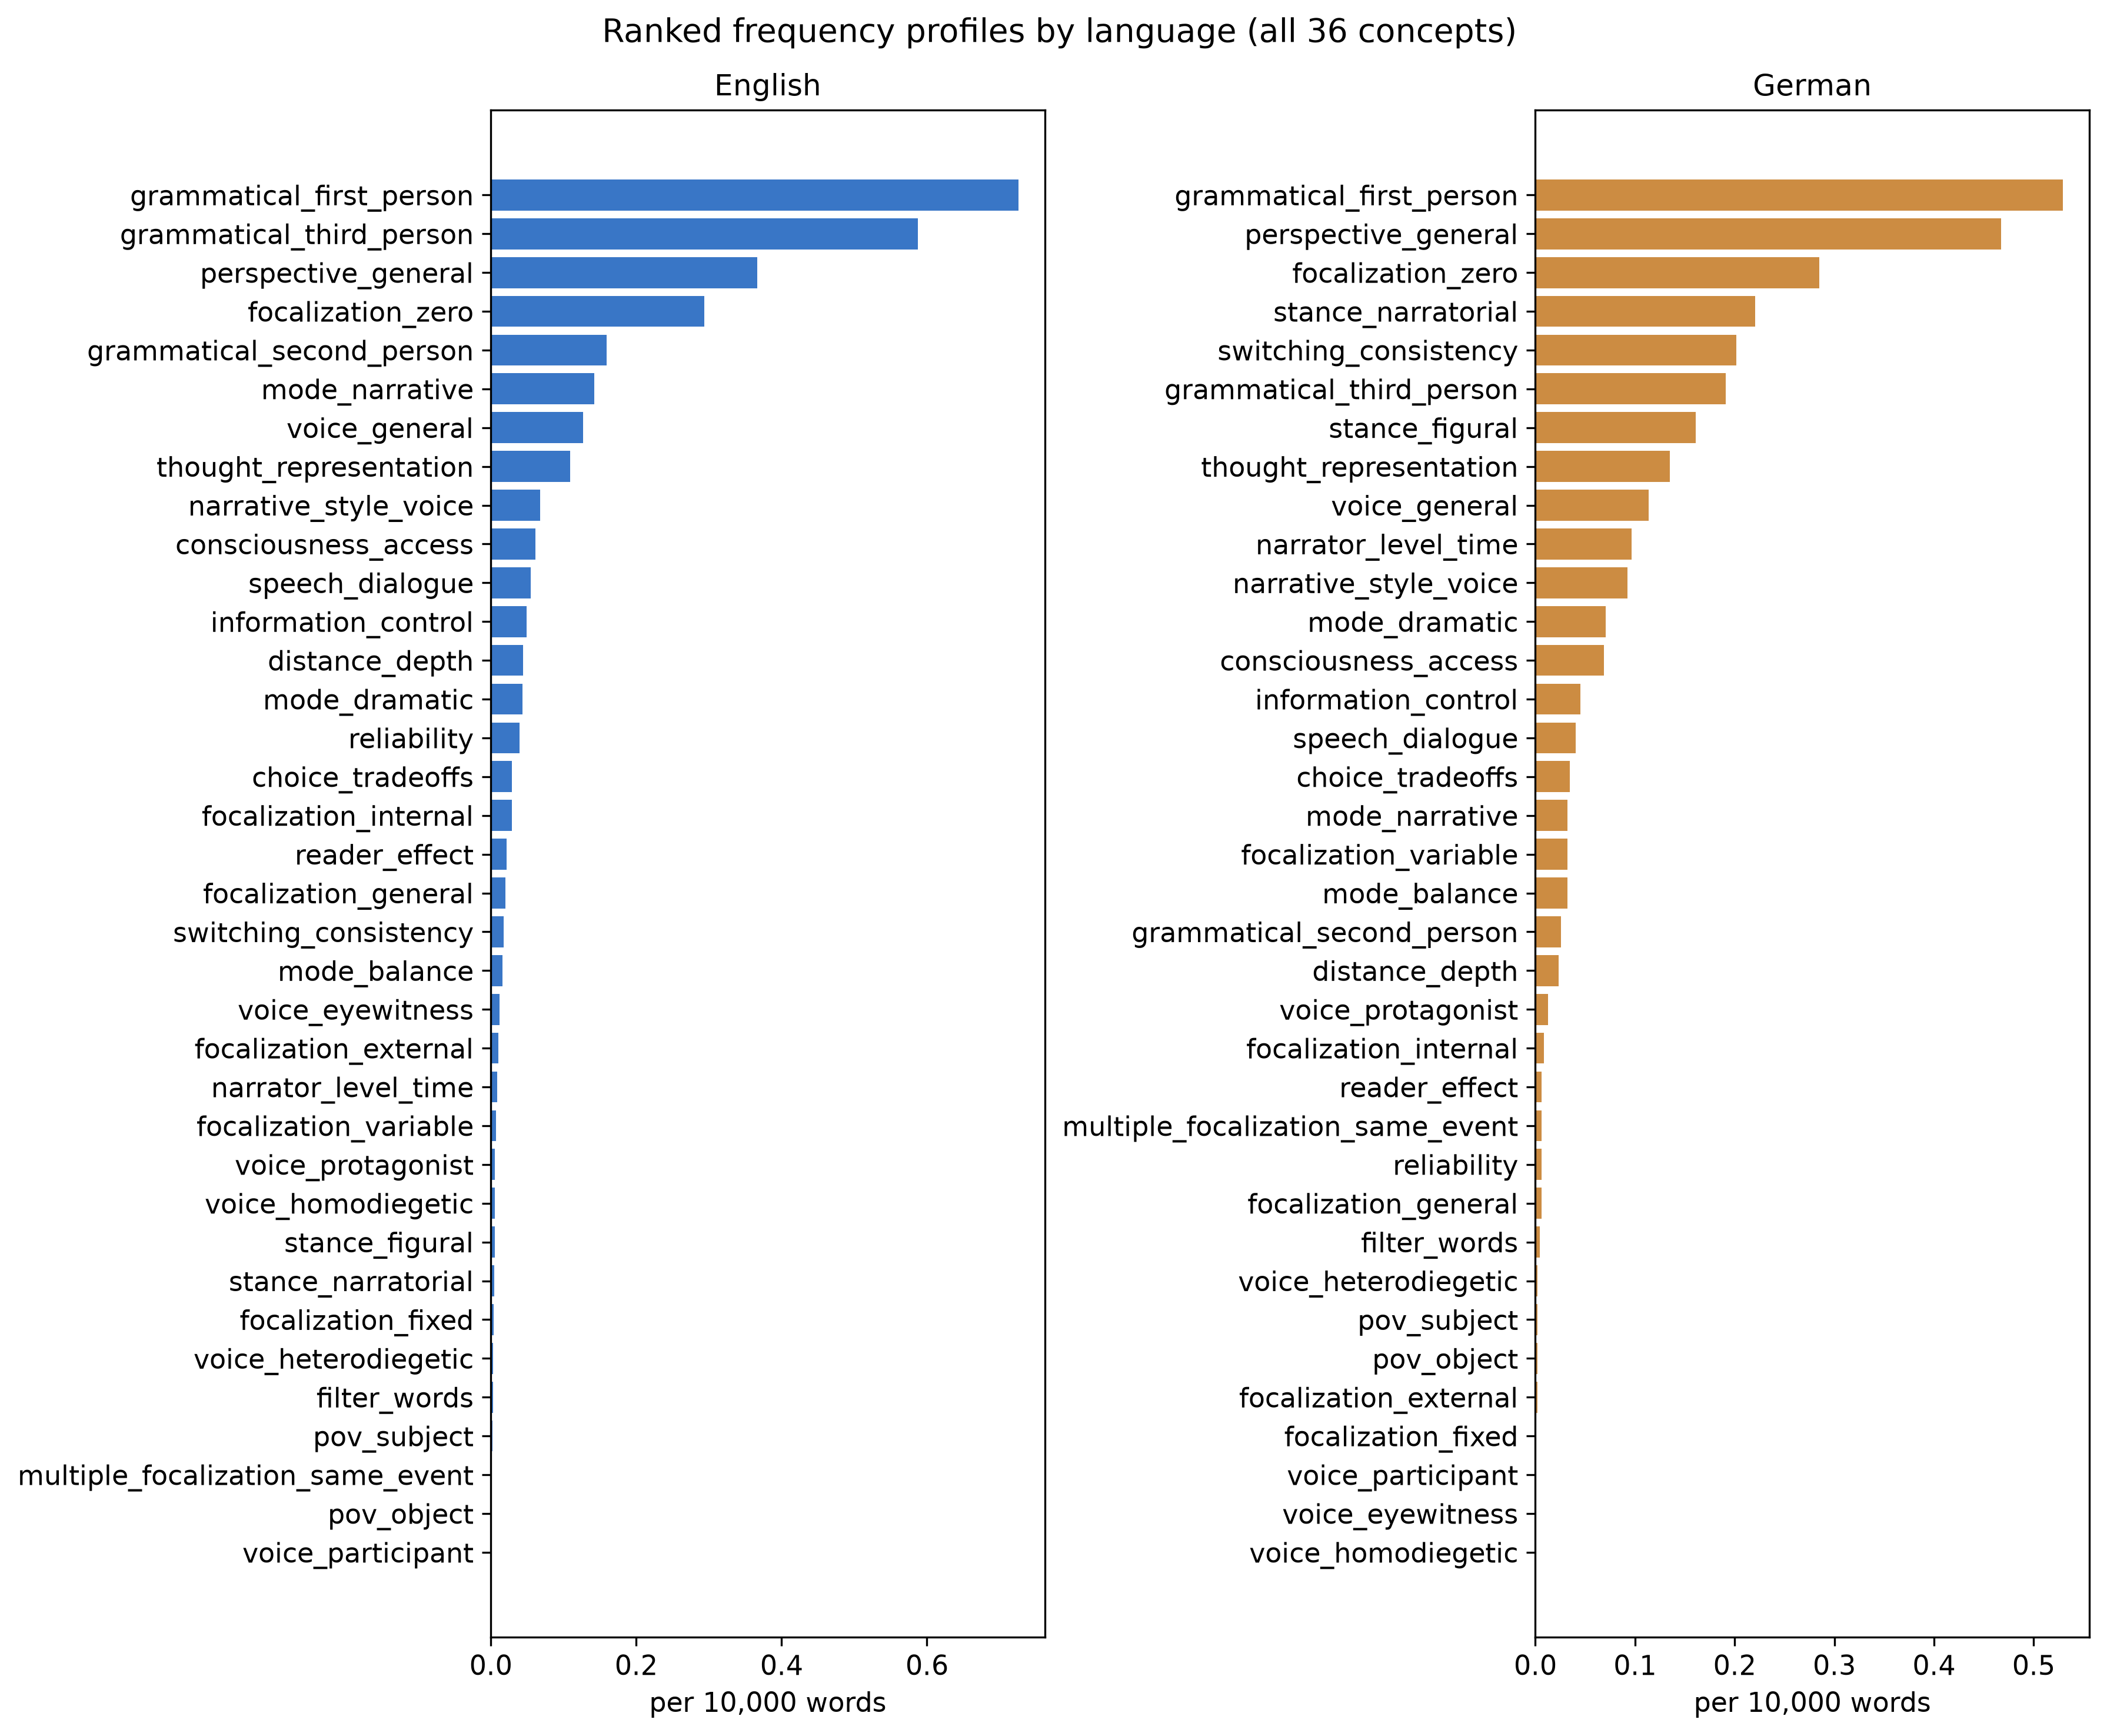

*Figure. Full ranked profiles for all 36 concepts.*

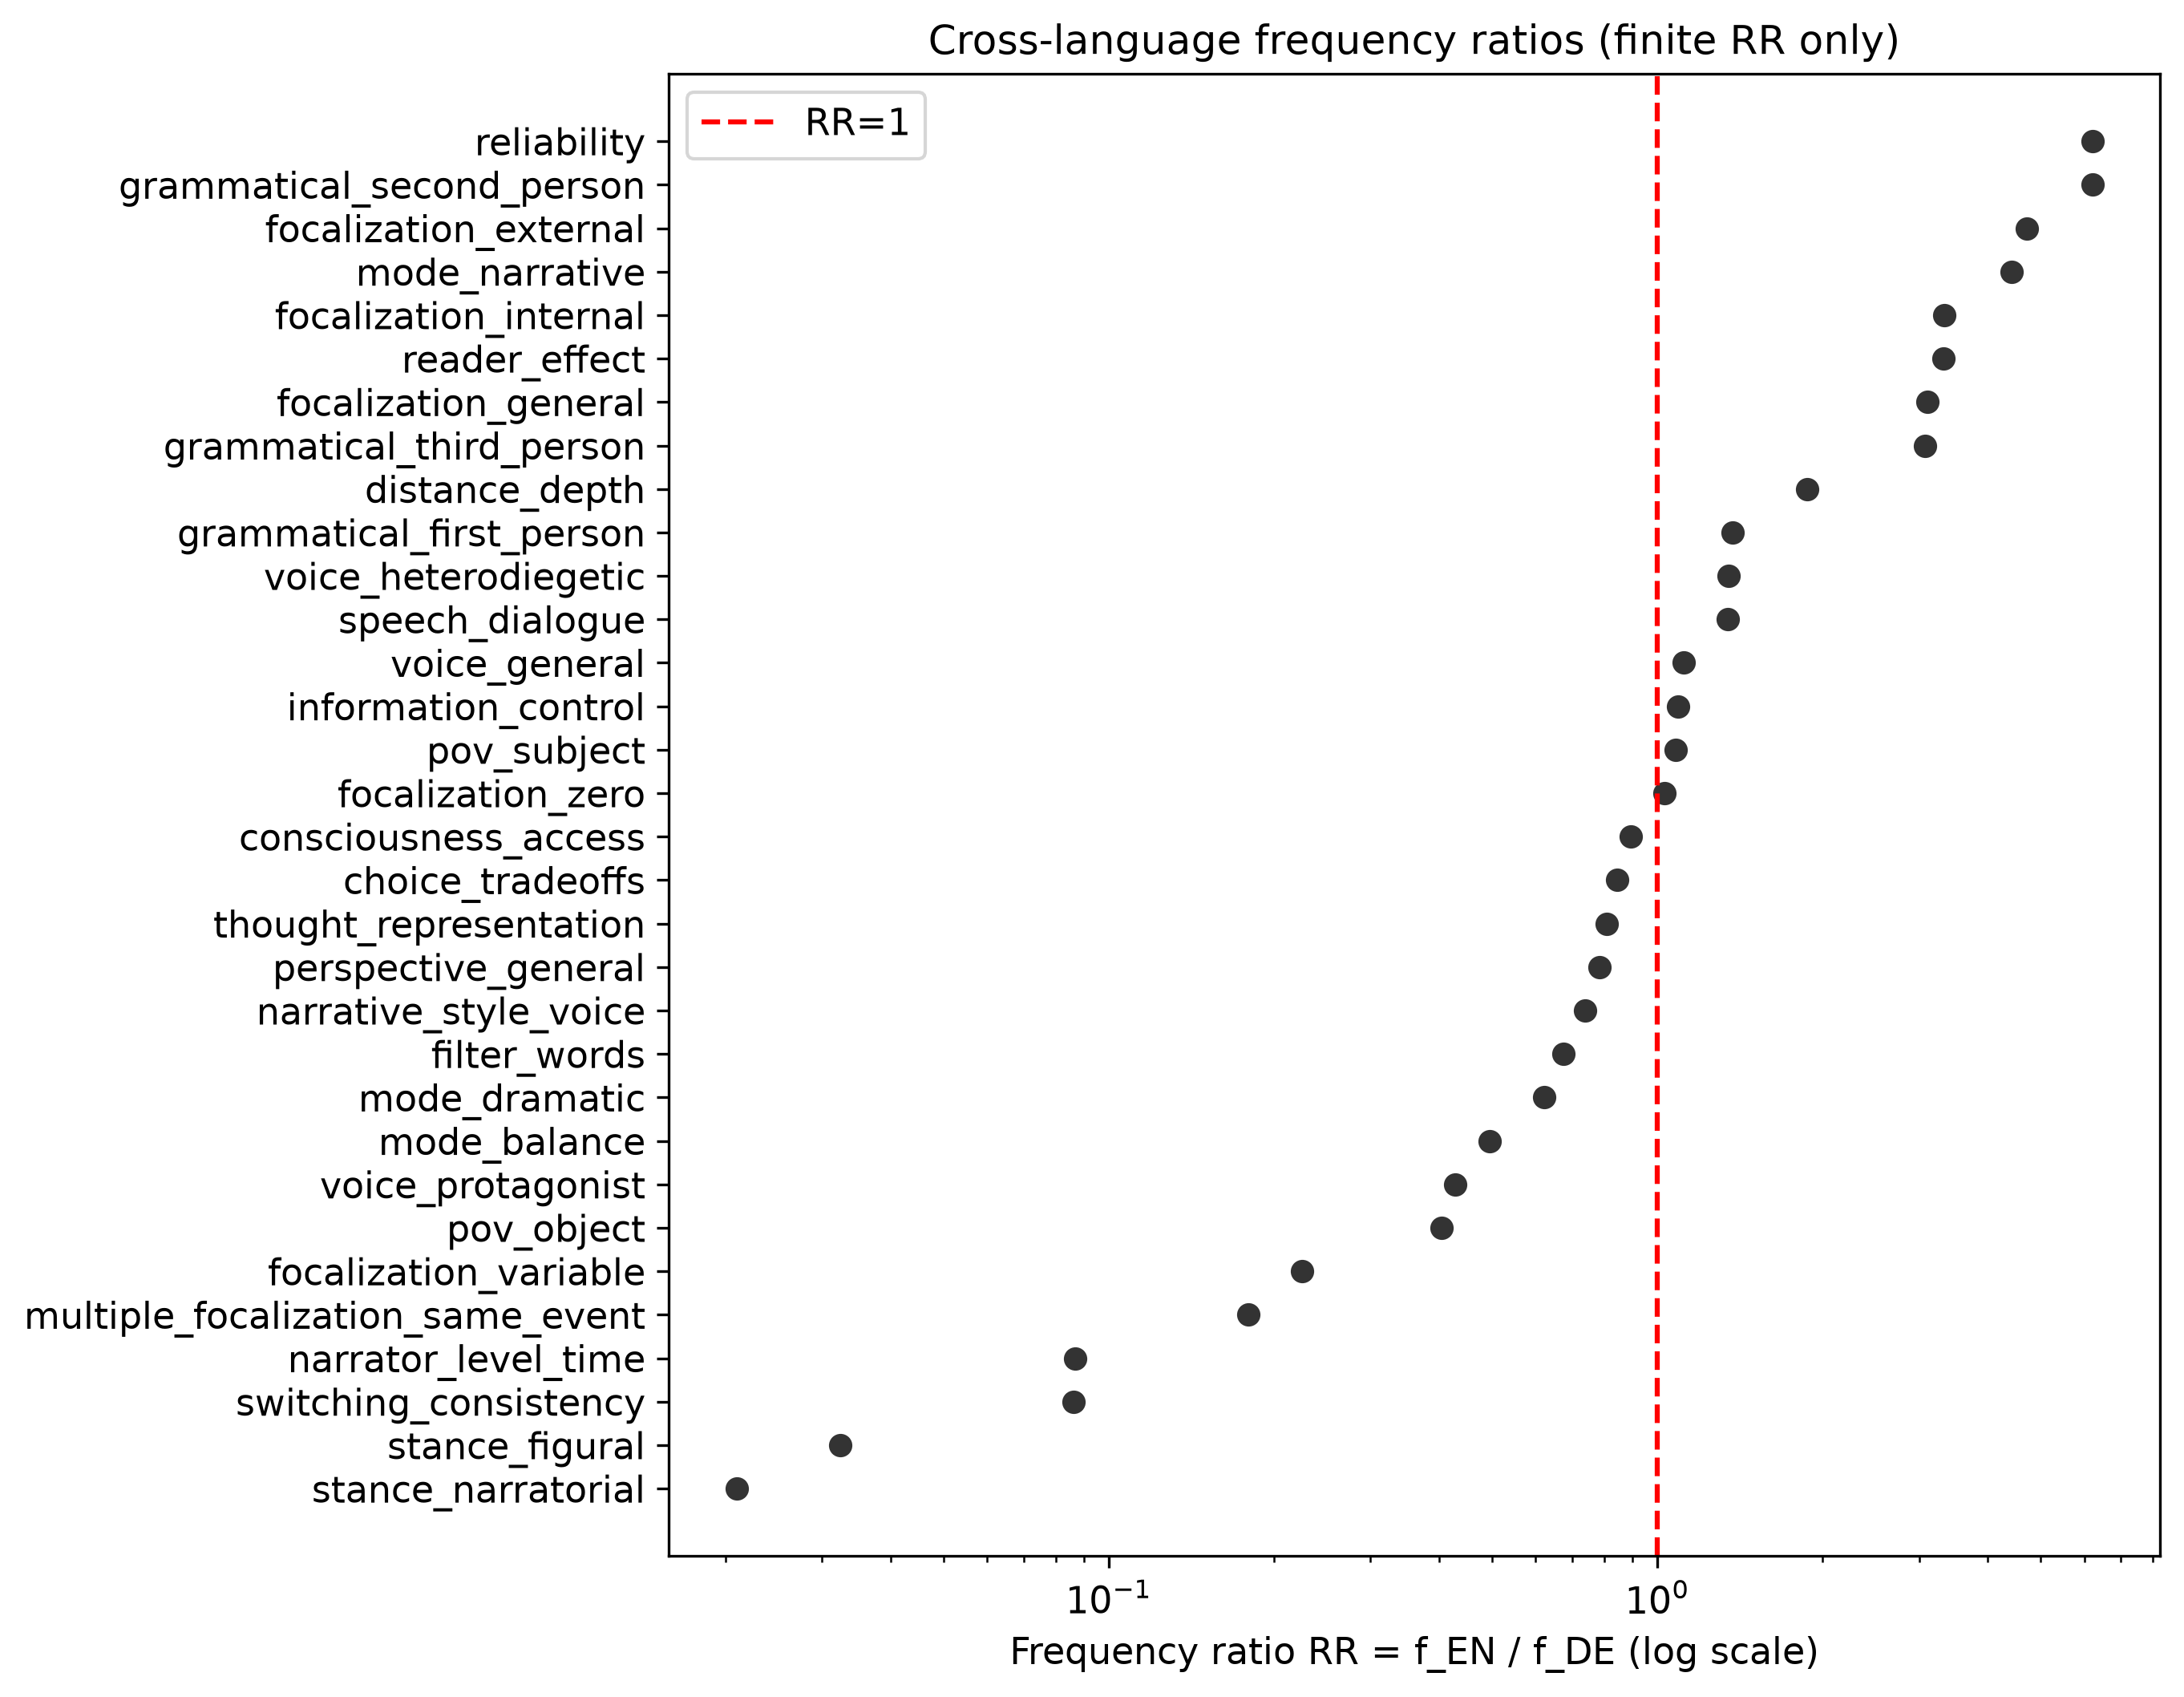

*Figure. RR = f_EN / f_DE on a log scale (finite ratios only; no pseudocounts).*

**Frequency ratio RR = f_EN / f_DE.** RR=1 equal rates; RR=2 English twice as high; RR=0.5 German twice as high. Concepts with zero in one language are omitted from the finite-RR plot rather than smoothed with arbitrary pseudocounts.

In [7]:
freq = load_t('concept_frequencies')
assert set(load_concept_ids()).issubset(set(freq.concept_id)), 'Missing concepts'
display(freq[['concept_id','concept_family','language_label','n_assignments','n_unique_passages','n_books',
              'frequency_per_10000_words','frequency_per_1000_paragraphs','percentage_of_books','median_book_frequency']]
        .sort_values(['language_label','frequency_per_10000_words'], ascending=[True, False])
        .head(20))
show_fig('07_concept_frequencies_top20', 'Top 20 concepts by maximum normalized frequency.')
show_fig('08_ranked_profiles', 'Full ranked profiles for all 36 concepts.')
show_fig('10_frequency_ratios', 'RR = f_EN / f_DE on a log scale (finite ratios only; no pseudocounts).')
display(Markdown(
    '**Frequency ratio RR = f_EN / f_DE.** RR=1 equal rates; RR=2 English twice as high; RR=0.5 German twice as high. '
    'Concepts with zero in one language are omitted from the finite-RR plot rather than smoothed with arbitrary pseudocounts.'
))


## 9. Concept families

Families provide an accessible overview. Family frequencies **deduplicate passages** within each family (they are not sums of concept frequencies).


,concept_family,concept_family_label,language,language_label,n_assignments,n_unique_passages,frequency_per_10000_words,note,method,version
0,perspective_and_person,Narrative perspective and grammatical person,en,English,6798,5178,1.497343,numerator = unique passages in family (dedupli...,lexical_v03,v03
1,perspective_and_person,Narrative perspective and grammatical person,de,German,619,494,1.058862,numerator = unique passages in family (dedupli...,lexical_v03,v03
2,narrator_participation,Narrator participation,en,English,92,89,0.025736,numerator = unique passages in family (dedupli...,lexical_v03,v03
3,narrator_participation,Narrator participation,de,German,7,7,0.015004,numerator = unique passages in family (dedupli...,lexical_v03,v03
4,narratorial_figural_stance,Narratorial and figural stance,en,English,34,34,0.009832,numerator = unique passages in family (dedupli...,lexical_v03,v03
5,narratorial_figural_stance,Narratorial and figural stance,de,German,178,155,0.332234,numerator = unique passages in family (dedupli...,lexical_v03,v03
6,focalization,Focalization,en,English,1273,1157,0.334574,numerator = unique passages in family (dedupli...,lexical_v03,v03
7,focalization,Focalization,de,German,161,155,0.332234,numerator = unique passages in family (dedupli...,lexical_v03,v03
8,mode_of_presentation,Mode of presentation,en,English,888,850,0.245798,numerator = unique passages in family (dedupli...,lexical_v03,v03
9,mode_of_presentation,Mode of presentation,de,German,82,79,0.169332,numerator = unique passages in family (dedupli...,lexical_v03,v03


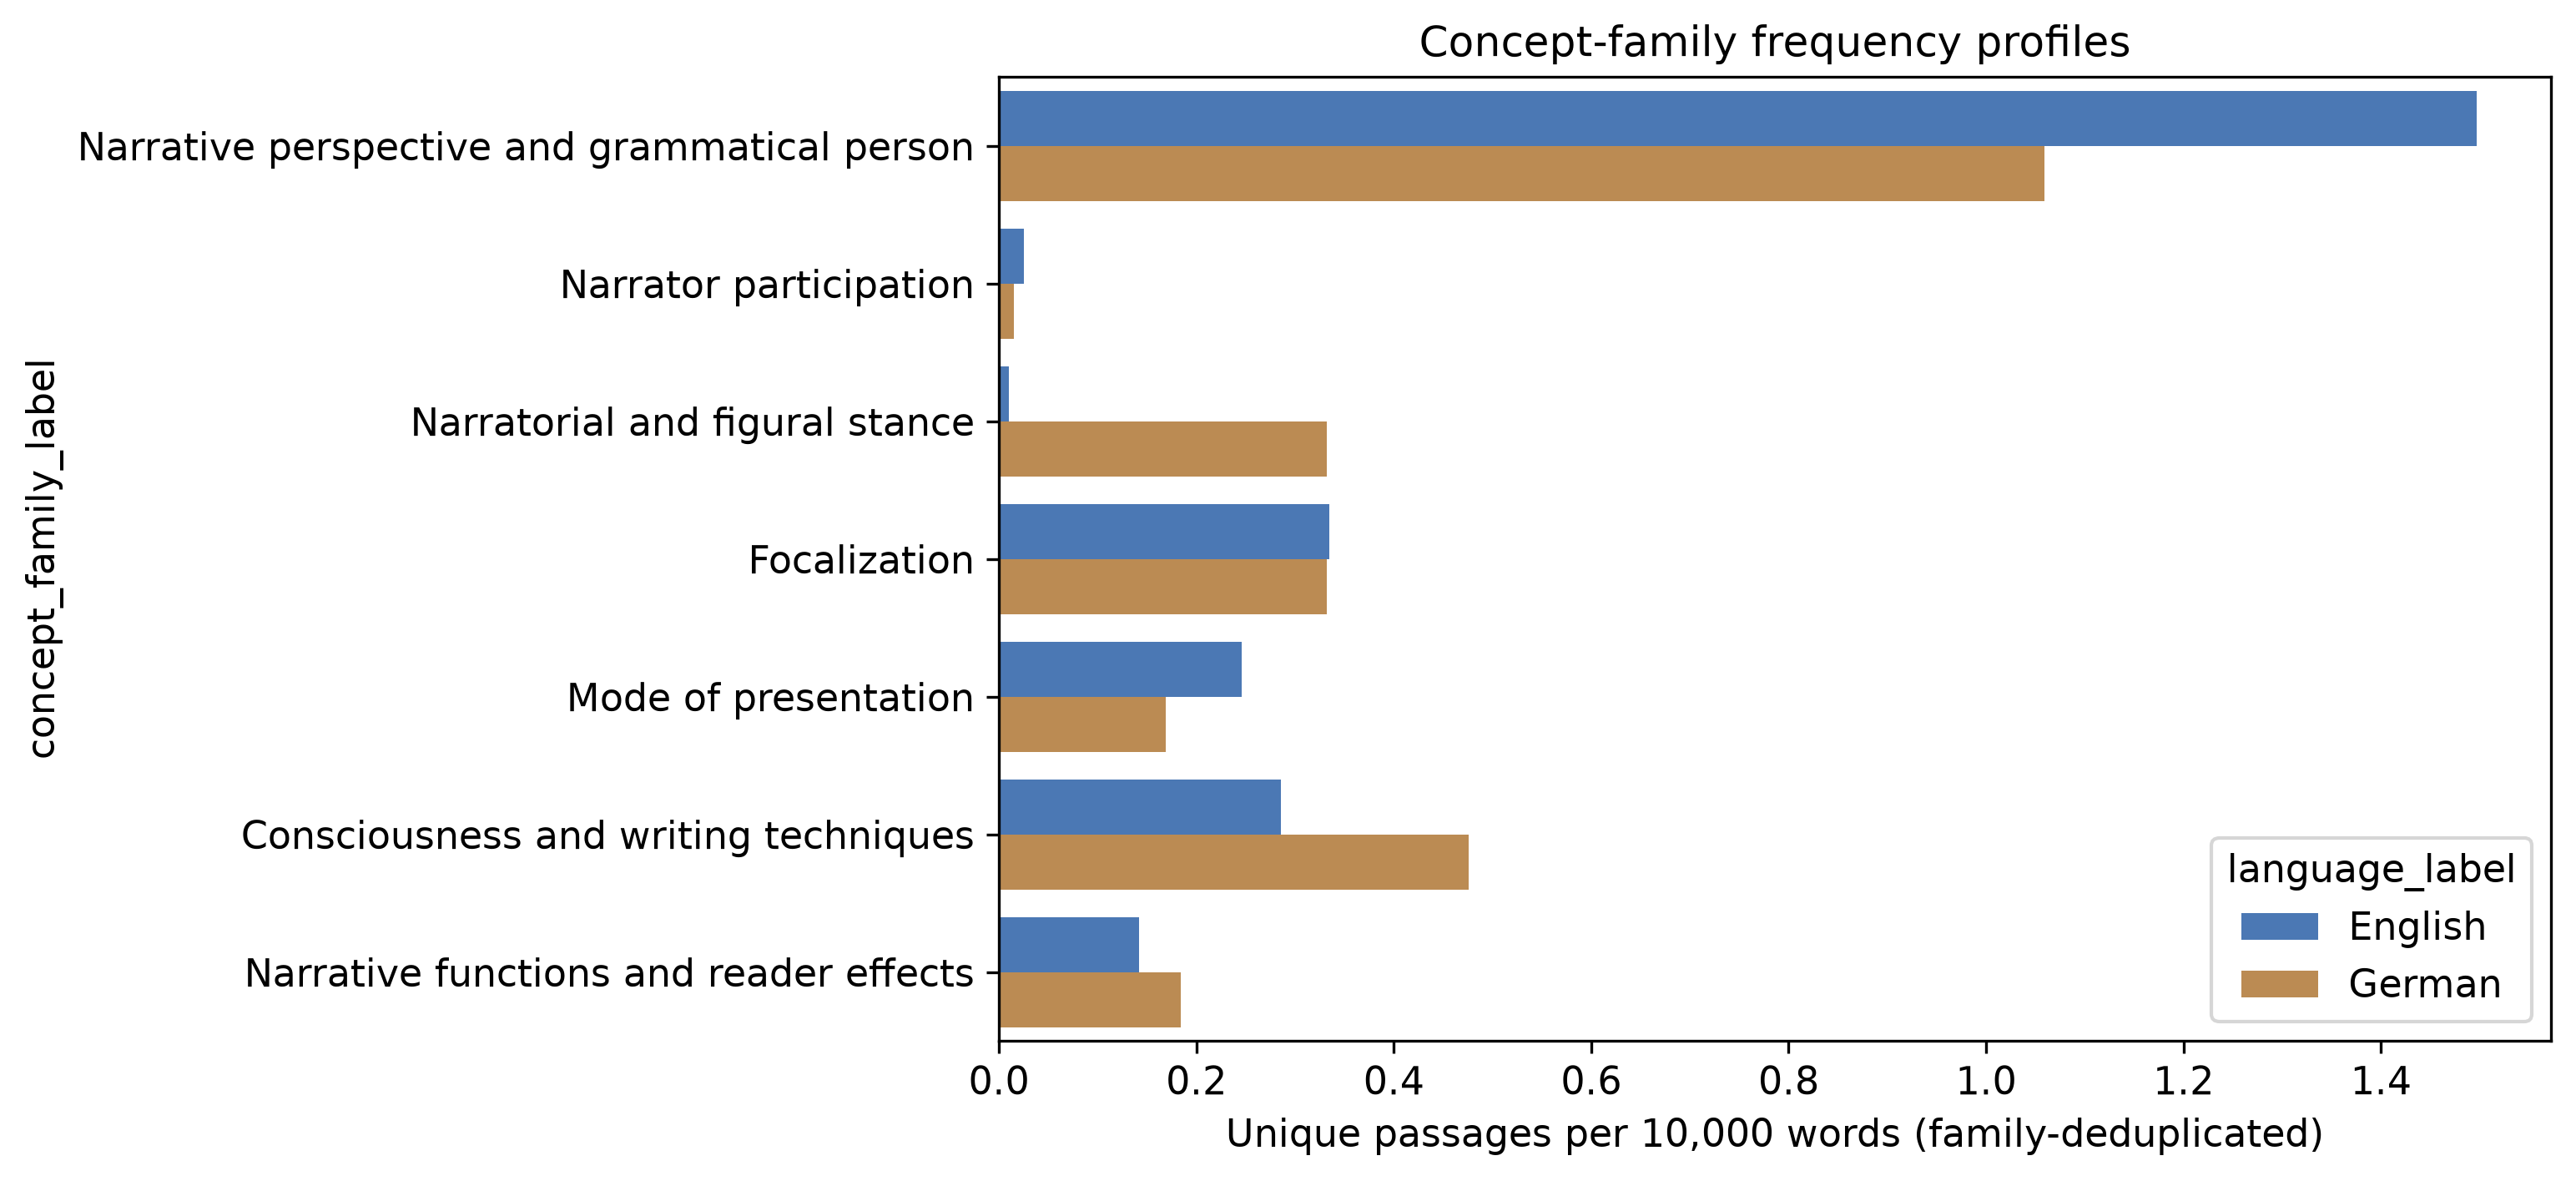

*Figure. Family-level unique-passage rates per 10,000 words.*

In [8]:
fam = load_t('concept_family_frequencies')
display(fam)
show_fig('09_family_frequencies', 'Family-level unique-passage rates per 10,000 words.')


## 10. Book-level frequency and dispersion

**Frequency** = how often a concept is identified. **Dispersion** = how broadly it is distributed across books. Medians include books with zero matches.


,concept_id,language,n_books_with_concept,pct_books_with_concept,mean_book_frequency,median_book_frequency,q1_book_frequency,q3_book_frequency,pct_books_zero,top5_books_contribution
2,grammatical_first_person,en,328,74.208145,0.789583,0.316370,0.0,1.043601,25.791855,0.103586
38,grammatical_first_person,de,47,70.149254,0.652759,0.298014,0.0,0.991416,29.850746,0.348178
4,grammatical_third_person,en,292,66.063348,0.625804,0.240170,0.0,0.891651,33.936652,0.125554
36,perspective_general,de,38,56.716418,0.603227,0.192079,0.0,0.794055,43.283582,0.357798
40,grammatical_third_person,de,34,50.746269,0.223193,0.047390,0.0,0.298872,49.253731,0.415730
49,focalization_zero,de,34,50.746269,0.292153,0.065835,0.0,0.458919,49.253731,0.458647
13,focalization_zero,en,199,45.022624,0.307206,0.000000,0.0,0.337943,54.977376,0.174213
62,switching_consistency,de,29,43.283582,0.204418,0.000000,0.0,0.175825,56.716418,0.691489
3,grammatical_second_person,en,170,38.461538,0.145998,0.000000,0.0,0.161130,61.538462,0.173913
46,stance_narratorial,de,25,37.313433,0.239410,0.000000,0.0,0.252003,62.686567,0.456311


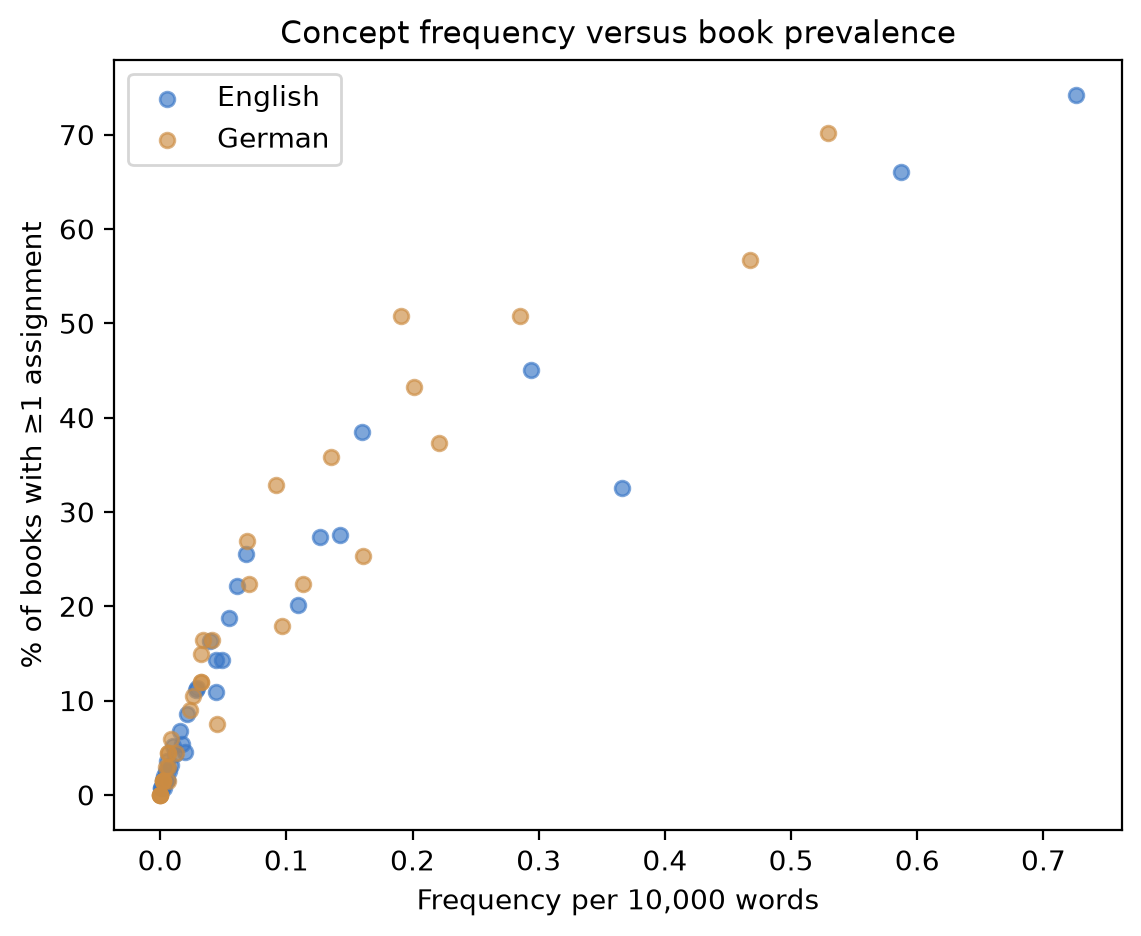

*Figure. Normalized frequency versus percentage of books containing the concept.*

Points in the upper-right are both frequent and widely dispersed. Points with high frequency but lower prevalence may be driven by a few books — inspect `top5_books_contribution` in the dispersion table.

In [9]:
disp = load_t('concept_dispersion')
display(disp.sort_values('pct_books_with_concept', ascending=False).head(12))
show_fig('12_freq_vs_prevalence', 'Normalized frequency versus percentage of books containing the concept.')
display(Markdown(
    'Points in the upper-right are both frequent and widely dispersed. '
    'Points with high frequency but lower prevalence may be driven by a few books — '
    'inspect `top5_books_contribution` in the dispersion table.'
))


## 11. Comparison by corpus category

Subgroup frequencies use **group-specific denominators**, not the full-language word total.


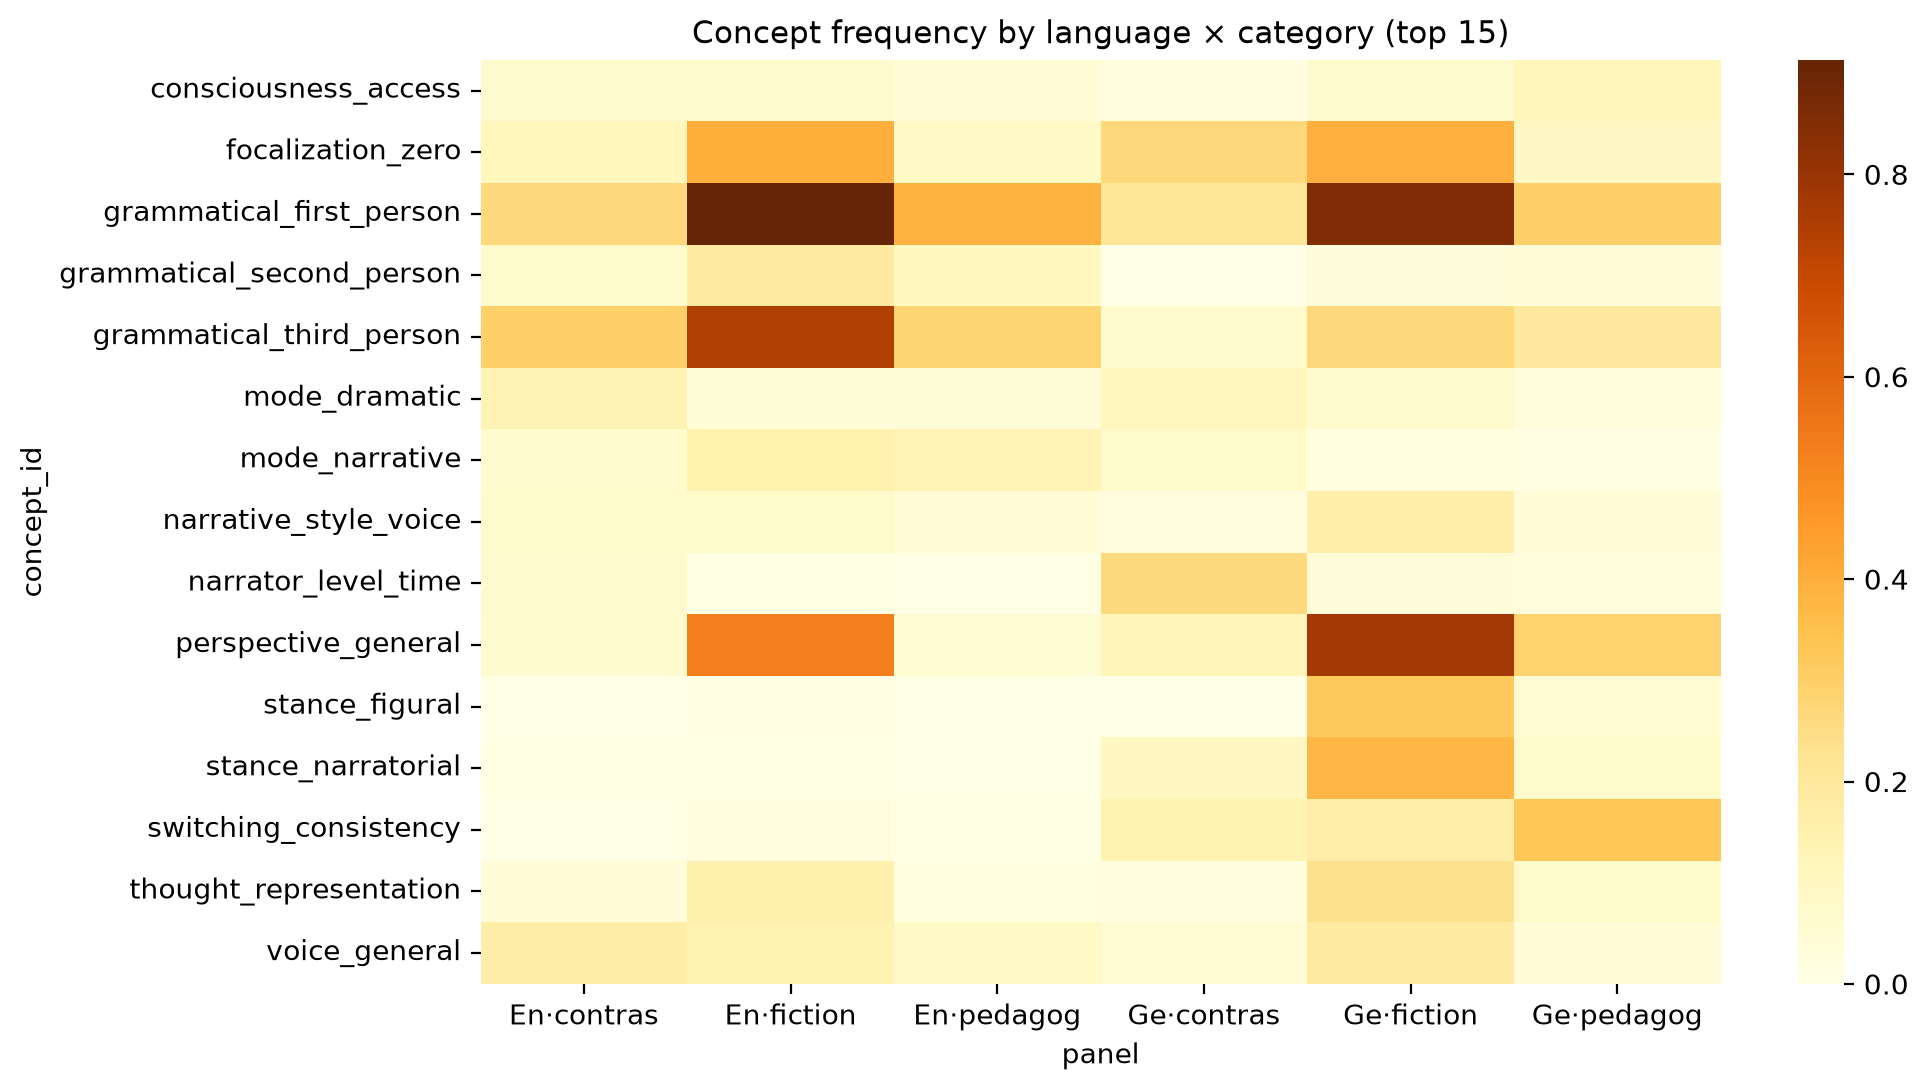

*Figure. Top concepts by language × corpus category (group-specific denominators).*

**Reference category weights for standardization** (mean of EN/DE word shares):

,common_weight
primary_group,
contrast,0.167980
fiction_manual,0.558011
pedagogy_genre_craft,0.274009


Standardization reduces the influence of unequal corpus composition but does **not** remove other biases (vocabulary coverage, retrieval rules, selection of manuals).

In [10]:
show_fig('11_heatmap_lang_group', 'Top concepts by language × corpus category (group-specific denominators).')
# Standardized comparison: common category weights (mean of EN/DE word shares).
comp = load_t('corpus_composition_by_group')
shares = comp.pivot(index='primary_group', columns='language', values='pct_words').fillna(0) / 100.0
w = shares.mean(axis=1)  # common reference weights
# Approximate standardized family rates using concept_frequencies filtered via heat is heavy;
# report category word weights used for standardization:
std_w = w.rename('common_weight')
display(Markdown('**Reference category weights for standardization** (mean of EN/DE word shares):'))
display(std_w.to_frame())
display(Markdown(
    'Standardization reduces the influence of unequal corpus composition but does **not** remove '
    'other biases (vocabulary coverage, retrieval rules, selection of manuals).'
))


## 12. Concept co-occurrence

Observation unit = unique passage. Jaccard \(J(A,B)=|A\cap B|/|A\cup B|\). High similarity on one or two passages is not a robust association.


**Strongest EN pairs (support ≥ 5):**

,language,concept_a,concept_b,cooccurrence,support_a,support_b,jaccard
41,en,grammatical_first_person,grammatical_third_person,882,2510,2031,0.241049
88,en,grammatical_third_person,focalization_zero,470,2031,1016,0.182383
66,en,grammatical_second_person,grammatical_third_person,243,552,2031,0.103846
47,en,grammatical_first_person,focalization_zero,324,2510,1016,0.101187
40,en,grammatical_first_person,grammatical_second_person,267,2510,552,0.095528
38,en,voice_general,narrative_style_voice,58,438,235,0.094309
133,en,focalization_internal,focalization_external,9,99,35,0.072000
118,en,focalization_zero,focalization_internal,67,1016,99,0.063931


**Strongest DE pairs (support ≥ 5):**

,language,concept_a,concept_b,cooccurrence,support_a,support_b,jaccard
18,de,voice_general,narrative_style_voice,22,53,43,0.297297
34,de,stance_narratorial,focalization_zero,36,103,133,0.180000
33,de,stance_narratorial,stance_figural,23,103,75,0.148387
5,de,perspective_general,stance_figural,37,218,75,0.144531
1,de,perspective_general,grammatical_first_person,55,218,247,0.134146
20,de,grammatical_first_person,grammatical_third_person,39,247,89,0.131313
45,de,focalization_variable,switching_consistency,12,15,94,0.123711
6,de,perspective_general,focalization_zero,37,218,133,0.117834


**Worked example:** concepts `grammatical_first_person` and `grammatical_third_person` co-occur in 882 passages; supports 2510 and 2031; Jaccard = 0.241.

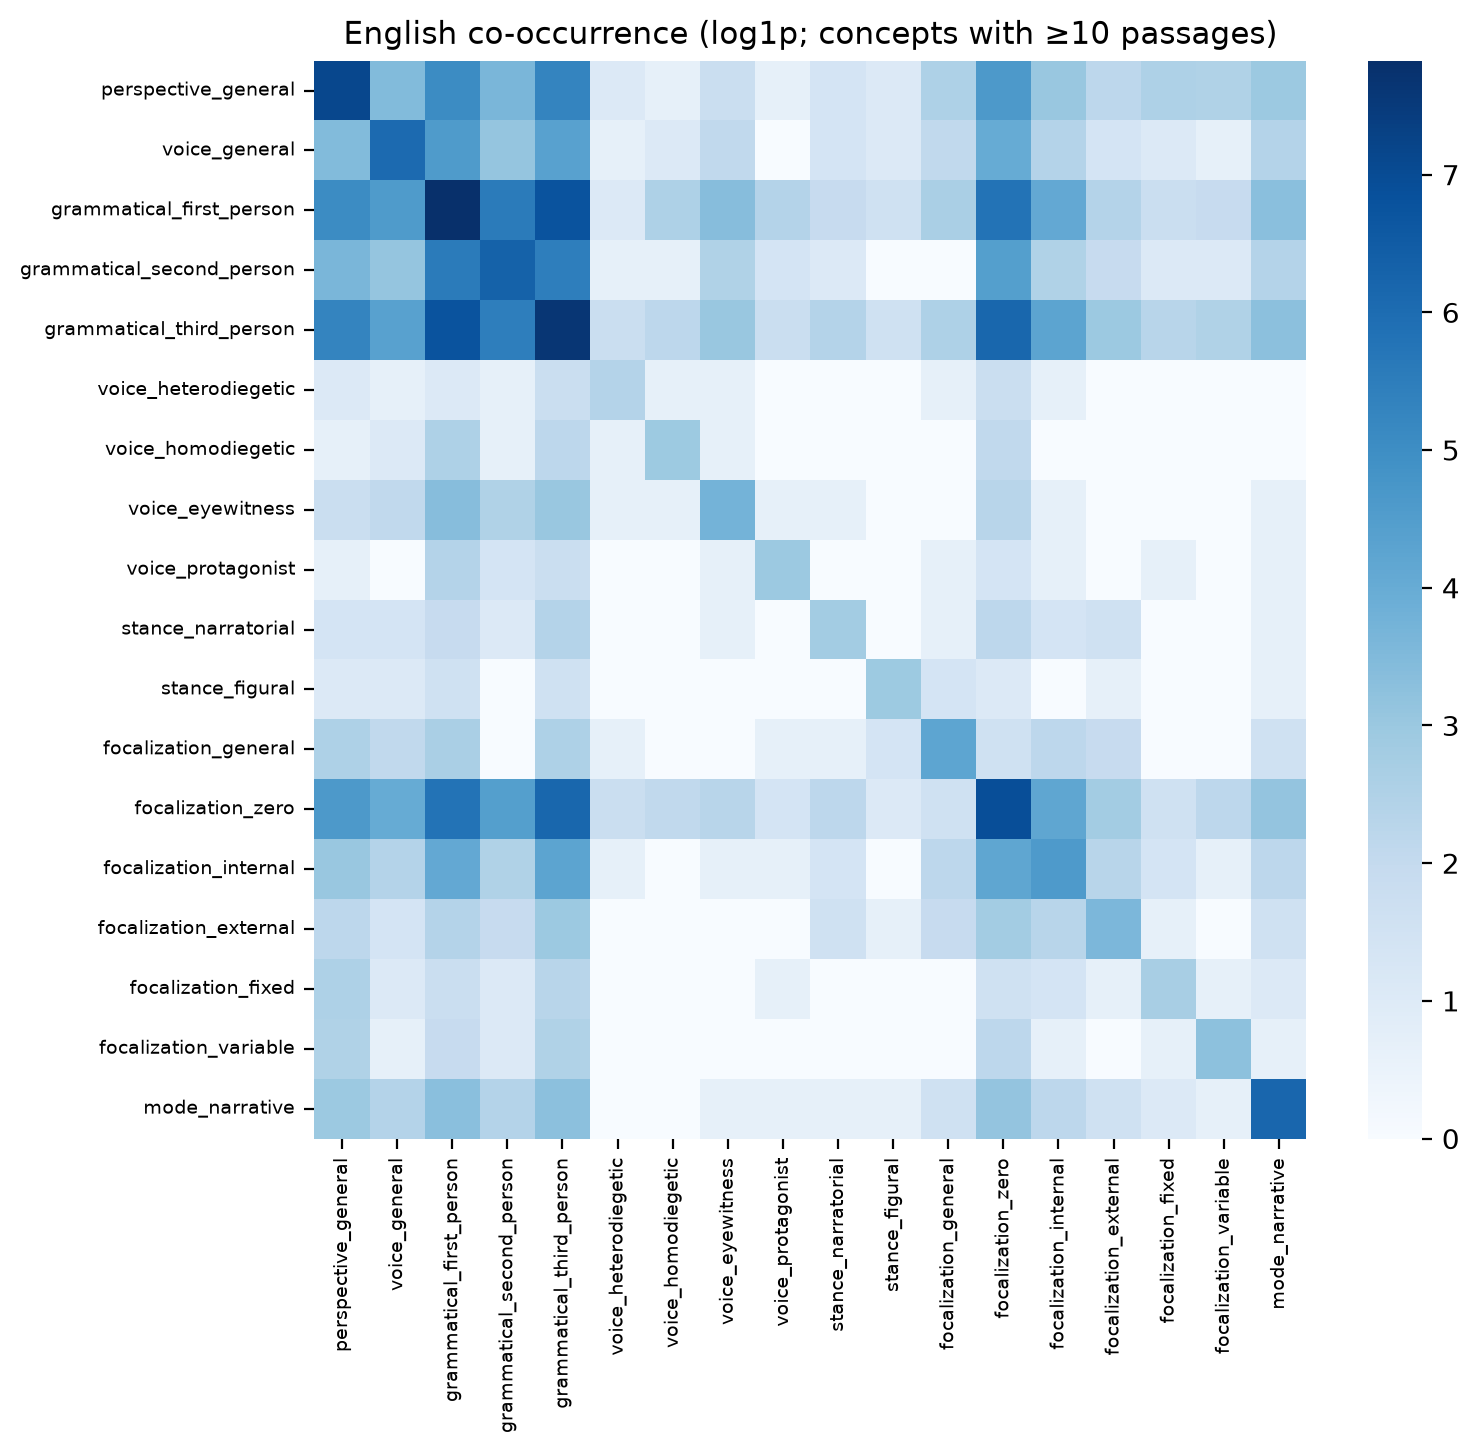

*Figure. English co-occurrence heatmap (log1p counts).*

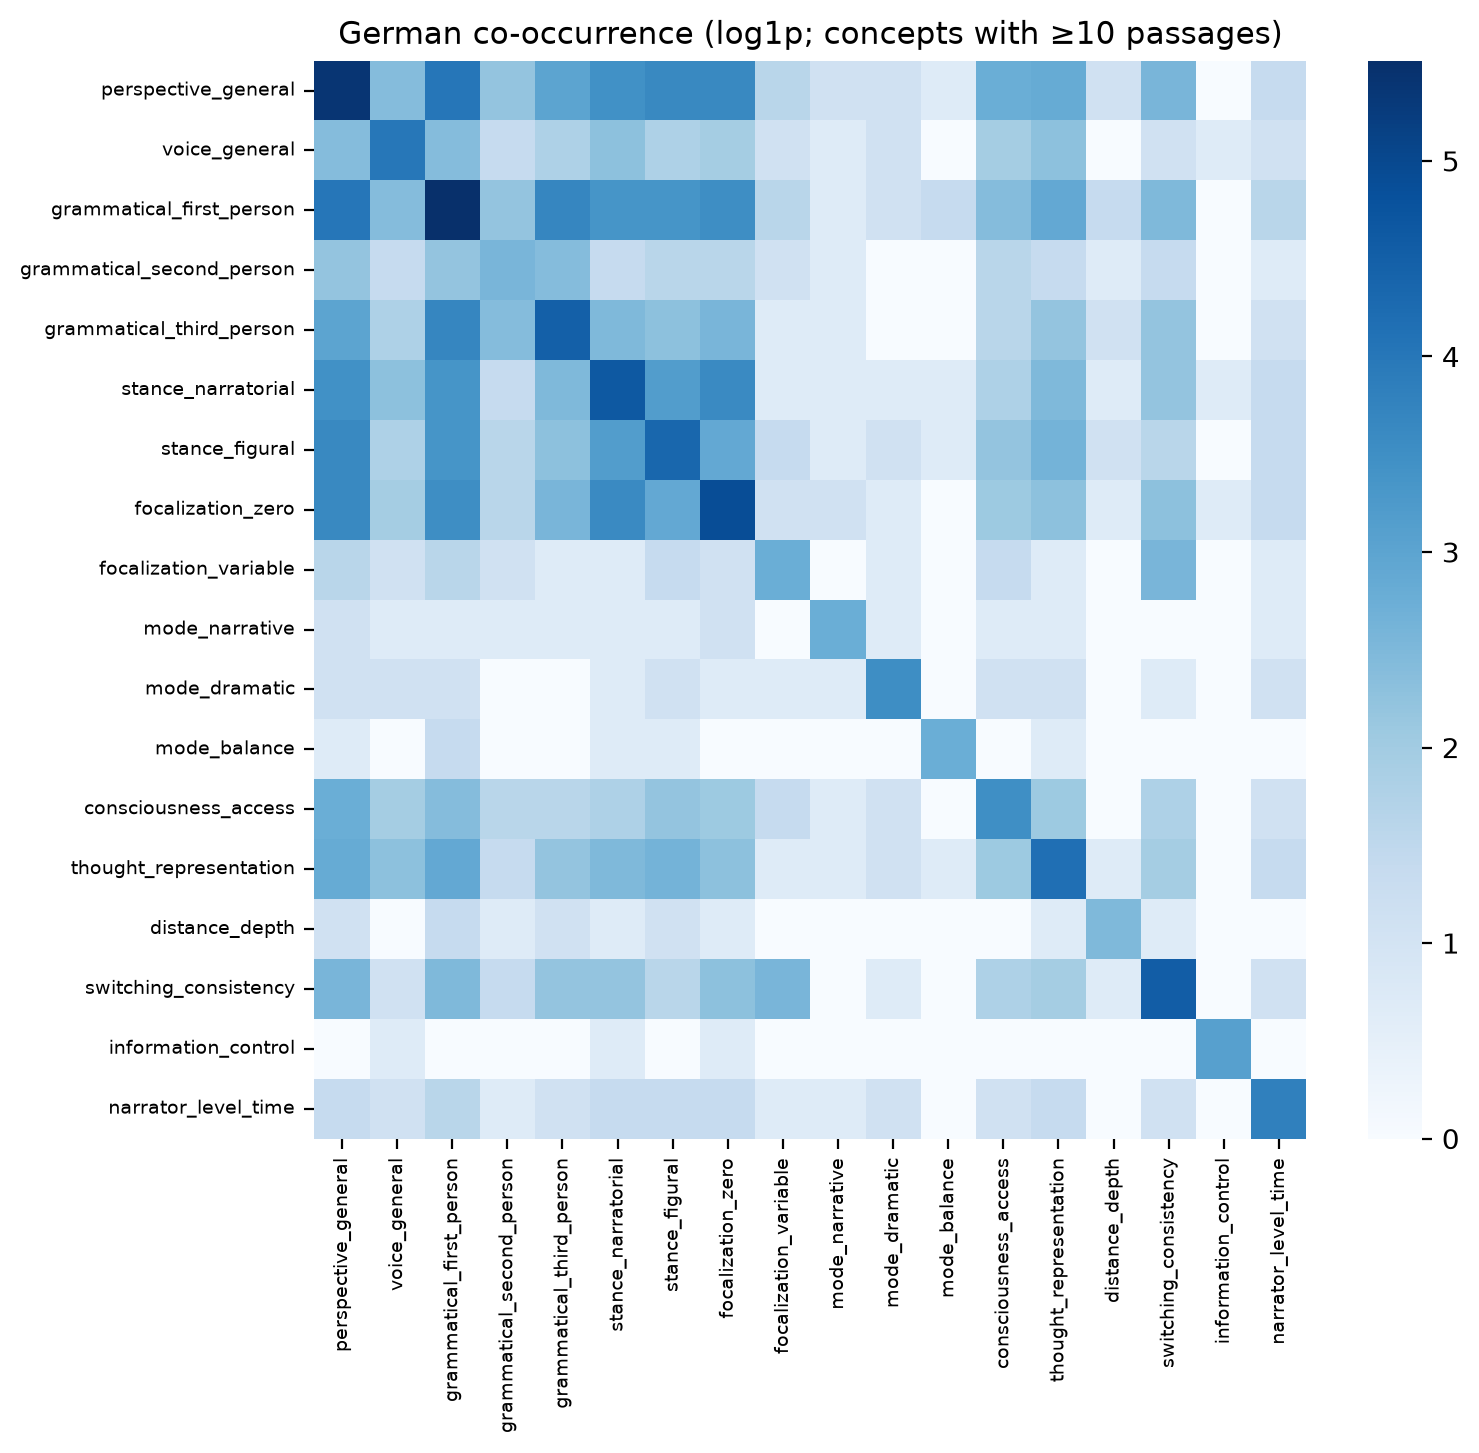

*Figure. German co-occurrence heatmap (log1p counts).*

Some co-occurrences may reflect overlapping lexical rules or the same expression mapped to multiple concepts. Repeat after excluding extreme-length paragraphs in sensitivity checks.

In [11]:
pairs_en = pd.read_csv(TABLES/'concept_cooccurrence_pairs_en.csv')
pairs_de = pd.read_csv(TABLES/'concept_cooccurrence_pairs_de.csv')
display(Markdown('**Strongest EN pairs (support ≥ 5):**'))
display(pairs_en.sort_values('jaccard', ascending=False).head(8))
display(Markdown('**Strongest DE pairs (support ≥ 5):**'))
display(pairs_de.sort_values('jaccard', ascending=False).head(8))
# Worked Jaccard example from actual data
ex = pairs_en.sort_values('cooccurrence', ascending=False).iloc[0]
display(Markdown(
    f"**Worked example:** concepts `{ex.concept_a}` and `{ex.concept_b}` co-occur in {int(ex.cooccurrence)} passages; "
    f"supports {int(ex.support_a)} and {int(ex.support_b)}; Jaccard = {ex.jaccard:.3f}."
))
show_fig('13_cooccurrence_en', 'English co-occurrence heatmap (log1p counts).')
show_fig('13_cooccurrence_de', 'German co-occurrence heatmap (log1p counts).')
display(Markdown(
    'Some co-occurrences may reflect overlapping lexical rules or the same expression mapped to multiple concepts. '
    'Repeat after excluding extreme-length paragraphs in sensitivity checks.'
))


## 13. Lexical retrieval and BM25 complementarity

Canonical key: `(passage_id, retrieval_concept_id)`. Additional BM25 candidates enlarge the explored pool but are **not yet independently validated**.


,language,language_label,n_lexical_assignments,n_lexical_passages,n_bnew_assignments,n_genuinely_new_bm25_passages,n_known_passages_with_new_bm25_concepts,n_combined_unique_passages,jaccard_passages_L_vs_Bnew,pool_note,method,version
0,en,English,10643,7380,2812,820,958,8200,0.116829,Bnew from bm25_only_unvalidated file (≈ Braw\\...,lexical_v03_vs_bm25_only_v03,v03
1,de,German,1380,941,3195,1263,330,2204,0.149728,Bnew from bm25_only_unvalidated file (≈ Braw\\...,lexical_v03_vs_bm25_only_v03,v03


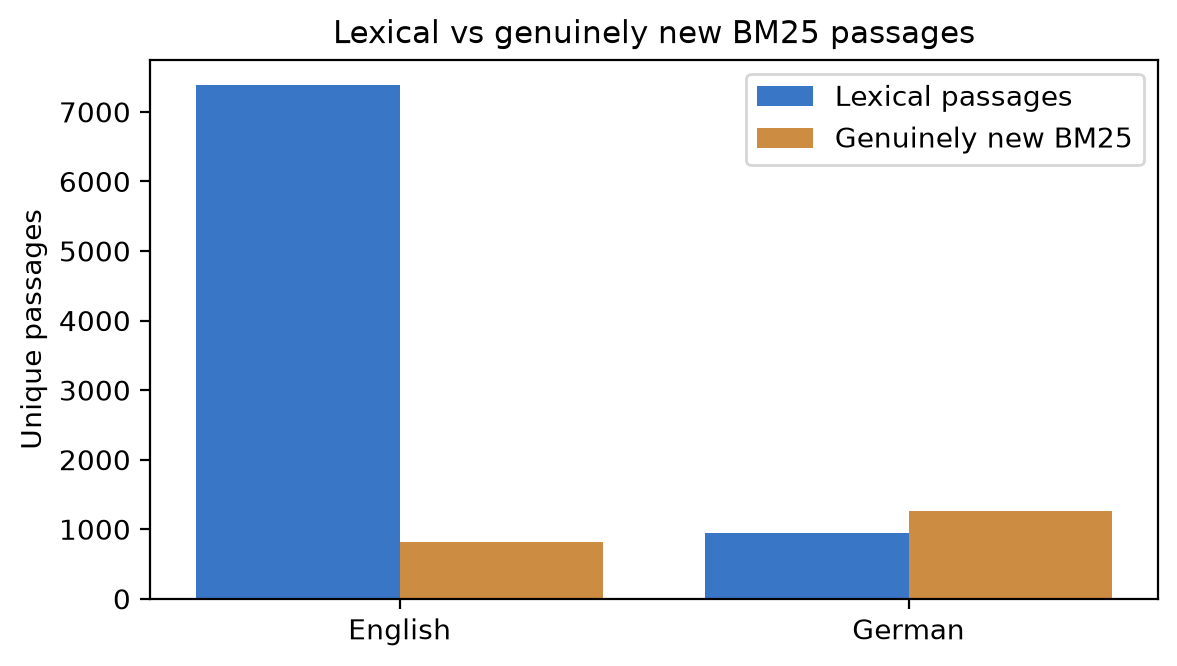

*Figure. Lexical passages versus genuinely new BM25 passages.*

German shows a substantially larger relative expansion via BM25. Possible influences: smaller corpus, different K limits (500 vs 100), query construction, dictionary coverage, morphology, and concept terminology. This does **not** prove that BM25 is inherently better for German. The reported pool uses the reconstructed B_combined / Bnew-file terminology (historical Braw not fully available).

In [12]:
comp = load_t('retrieval_complementarity')
display(comp)
show_fig('14_complementarity', 'Lexical passages versus genuinely new BM25 passages.')
display(Markdown(
    'German shows a substantially larger relative expansion via BM25. Possible influences: smaller corpus, '
    'different K limits (500 vs 100), query construction, dictionary coverage, morphology, and concept terminology. '
    'This does **not** prove that BM25 is inherently better for German. '
    'The reported pool uses the reconstructed B_combined / Bnew-file terminology (historical Braw not fully available).'
))


## 14. German terminology and qualitative analysis

The German audit (78 passages) is a **lexicon-development** dataset with `heuristic_provisional_assessment`. The heuristic share labelled “genuine” must **not** be read as precision. Human-review fields are empty.


In [13]:
audit = pd.read_csv(DATA_INTERIM/'retrieval'/'german_audit_review_v05.csv', dtype=str).fillna('')
display(audit['heuristic_provisional_category'].value_counts().to_frame('n'))
# Representative qualitative cases WITHOUT source text (copyright).
cases = audit[['passage_id','trigger','predicted_concepts','heuristic_provisional_category',
               'concept_assignment_ambiguity','heuristic_provisional_notes']].copy()
cases = cases.rename(columns={
    'predicted_concepts':'retrieved_concept',
    'heuristic_provisional_category':'possible_interpretation',
    'concept_assignment_ambiguity':'alternative_interpretation',
})
cases['human_review_required'] = True
cases['notes'] = 'AI/heuristic interpretation only; no copyrighted passage text shown.'
display(cases.head(12))
wiss = audit[audit.trigger.str.contains('wissensvorsprung', case=False, na=False)]
display(Markdown(
    f'**Wissensvorsprung rows:** {len(wiss)}. These may discuss dramatic irony / audience knowledge / '
    'information asymmetry and may be relevant to `information_control` or `reader_effect` even if '
    'focalization relevance is uncertain. They are not auto-marked unrelated.'
))


,n
heuristic_provisional_category,
genuine_narratological_discussion,71
unrelated_or_unclear,6
general_literary_discussion,1


,passage_id,trigger,retrieved_concept,possible_interpretation,alternative_interpretation,heuristic_provisional_notes,human_review_required,notes
0,de_d88c45142668:c1:p73,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
1,de_f03df72445ee:c68:p8,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
2,de_017250902eee:c29:p36,allwissen,focalization_zero;grammatical_third_person,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
3,de_a70e5a5cb1ca:c43:p14,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
4,de_809a3ef948a5:c19:p1,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
5,de_d88c45142668:c1:p368,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
6,de_d88c45142668:c1:p540,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
7,de_c2147905f44d:c0:p67,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
8,de_bef6dde900a8:c0:p107,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...
9,de_37f3f9d87441:c11:p22,allwissen,focalization_zero,genuine_narratological_discussion,,,True,AI/heuristic interpretation only; no copyright...


**Wissensvorsprung rows:** 7. These may discuss dramatic irony / audience knowledge / information asymmetry and may be relevant to `information_control` or `reader_effect` even if focalization relevance is uncertain. They are not auto-marked unrelated.

## 15. Exploratory historical overview

Publication year ≠ edition year. Strong claims about historical change are premature until German date coverage improves.


In [14]:
# Dated vs undated by decade (analysis set)
rows=[]
for lang,label in LANG_LABEL.items():
    al = a[a.language==lang]
    years = pd.to_numeric(al.publication_year, errors='coerce')
    undated = int(years.isna().sum())
    dated = al.loc[years.notna()].copy()
    dated['decade'] = (years.dropna()//10*10).astype(int)
    for dec, g in dated.groupby('decade'):
        rows.append({'language':label,'decade':int(dec),'n_books':len(g),
                     'words':int(pd.to_numeric(g.number_of_words, errors='coerce').fillna(0).sum())})
    rows.append({'language':label,'decade':'undated','n_books':undated,'words':None})
hist = pd.DataFrame(rows)
display(hist.head(20))
display(Markdown('Future questions (not established trends): deep POV; omniscient narrators; immersion; perspective-switching advice; filter-word terminology.'))


,language,decade,n_books,words
0,English,1960,8,640559.0
1,English,1970,12,611457.0
2,English,1980,45,3240697.0
3,English,1990,68,5679588.0
4,English,2000,105,9273212.0
5,English,2010,77,5421663.0
6,English,2020,2,248718.0
7,English,undated,125,NaN
8,German,1980,1,46126.0
9,German,1990,3,186429.0


Future questions (not established trends): deep POV; omniscient narrators; immersion; perspective-switching advice; filter-word terminology.

## 16. Sensitivity analysis

Primary analysis is not replaced by whichever scenario looks most interesting.


,scenario,scenario_description,concept_id,freq_en_per_10k,freq_de_per_10k,frequency_ratio_en_over_de,method,version
0,S1,Complete analysis-set corpus,focalization_zero,0.293801,0.285078,1.030597,lexical_v03,v03
1,S1,Complete analysis-set corpus,stance_narratorial,0.004627,0.220775,0.020957,lexical_v03,v03
2,S1,Complete analysis-set corpus,stance_figural,0.005205,0.160758,0.032379,lexical_v03,v03
3,S1,Complete analysis-set corpus,grammatical_third_person,0.587312,0.190767,3.078694,lexical_v03,v03
4,S1,Complete analysis-set corpus,filter_words,0.002892,0.004287,0.674554,lexical_v03,v03
5,S1,Complete analysis-set corpus,reader_effect,0.021399,0.006430,3.327799,lexical_v03,v03
6,S2,Primary creative writing manuals only (exclude...,focalization_zero,0.303321,0.290995,1.042359,lexical_v03,v03
7,S2,Primary creative writing manuals only (exclude...,stance_narratorial,0.004568,0.269995,0.016919,lexical_v03,v03
8,S2,Primary creative writing manuals only (exclude...,stance_figural,0.005482,0.224996,0.024364,lexical_v03,v03
9,S2,Primary creative writing manuals only (exclude...,grammatical_third_person,0.602683,0.239996,2.511224,lexical_v03,v03


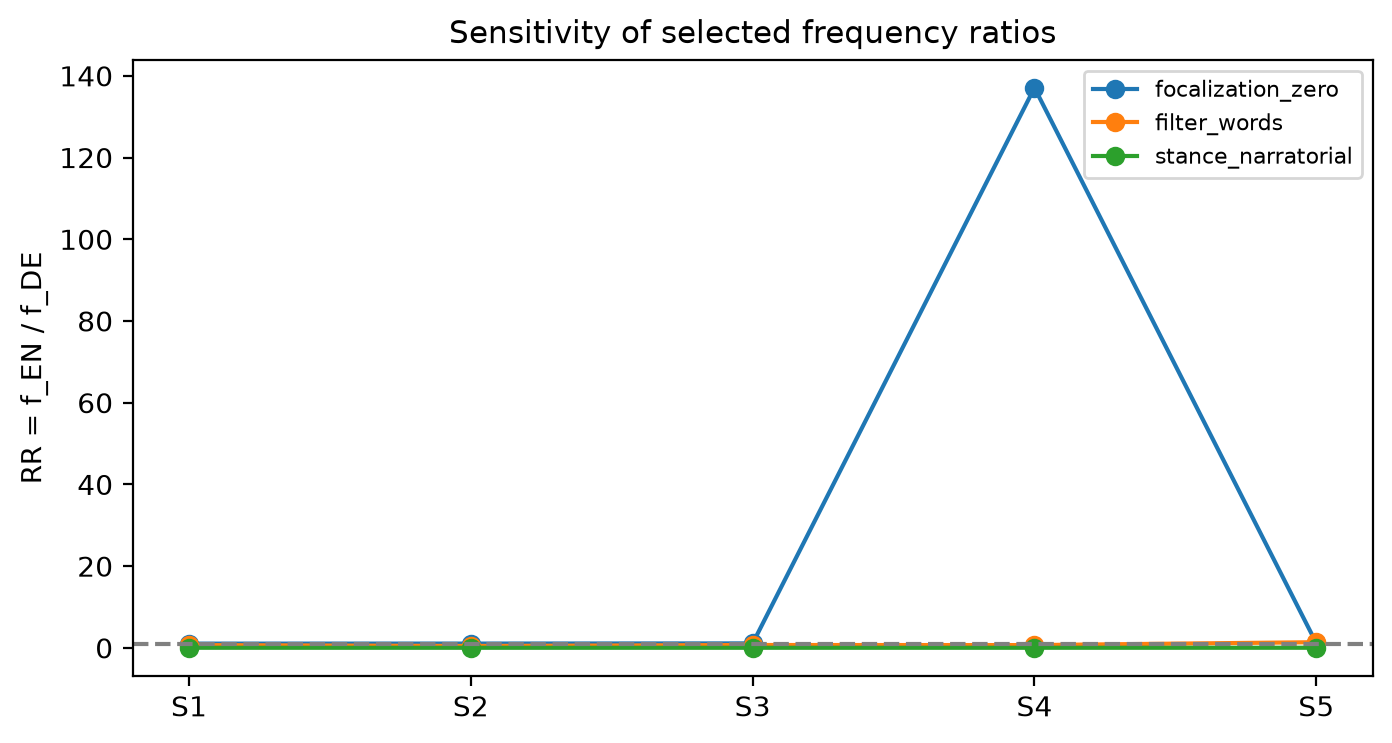

*Figure. Selected EN/DE frequency ratios under scenarios S1–S5.*

**Scenarios:** S1 full analysis set; S2 exclude contrast; S3 exclude extreme-length passages (numerator and denominator); S4 conservative DE allwissen/focalization_zero exclusions; S5 exclude possible-duplicate books.

Findings that reverse direction or become unstable under S2/S4 should be treated cautiously.

In [15]:
sens = load_t('sensitivity_analysis')
display(sens.head(15))
show_fig('16_sensitivity_rr', 'Selected EN/DE frequency ratios under scenarios S1–S5.')
display(Markdown('''**Scenarios:** S1 full analysis set; S2 exclude contrast; S3 exclude extreme-length passages (numerator and denominator); S4 conservative DE allwissen/focalization_zero exclusions; S5 exclude possible-duplicate books.

Findings that reverse direction or become unstable under S2/S4 should be treated cautiously.'''))


## 17. Statistical methods and interpretation

| Method | Purpose |
|---|---|
| Absolute counts | Observed quantity of candidate material |
| Normalized frequencies | Compare populations of different sizes |
| Frequency ratios | Magnitude/direction of differences |
| Mean/median/quartiles | Typical book-level frequencies and spread |
| Book prevalence | Distribution across the corpus |
| Jaccard | Overlap of concept passage sets |
| Stratified analysis | Compare equivalent corpus categories |
| Sensitivity analysis | Robustness to analytical decisions |

We do **not** report precision, recall, F1 or ranking metrics as observed research results until manual evaluation data are available. No significance testing is introduced merely because libraries make it easy.


## 18. Discussion and preliminary conclusions

### Corpus-related observations
The English analysis set is much larger. German contrast materials form a far larger word share. Publication-year and work-level identifiers are incomplete, especially for German.

### Narratological observations (retrieval coverage only)
Concept profiles suggest shared attention to person, stance and focalization vocabulary, with language-specific terminology (e.g. German Stanzel-related cues) driving some German gains after v0.3 lexicon expansion. These are **observed retrieval patterns**, not validated prevalence.

### Pedagogical observations
Category heatmaps suggest fiction manuals and pedagogy/craft materials emphasize partly different concept bundles; contrast materials can inflate theoretical vocabulary rates.

### Methodological observations
Lexical rules, evidence tiers and BM25 expand the candidate pool differently by language. German BM25 expansion is relatively larger; causes are plural. The German heuristic audit must not be mistaken for evaluation precision.

### Future work
Semantic retrieval and human annotation could identify alternative phrasings, reduce vocabulary bias, improve rare-concept coverage, validate relevance, and support stronger cross-linguistic comparisons.

**For every conclusion:** distinguish what was directly observed, what is a plausible interpretation, and what requires additional evidence.


In [16]:
# Final integrity checks
concepts = load_concept_ids()
assert len(concepts)==36
assert freq.concept_id.nunique()==36
assert set(freq.language)=={'en','de'}
cov2 = load_t('retrieval_coverage')
assert abs(cov2.loc[cov2.language=='English','retrieved_passages'].iloc[0] - 7380) < 1 or True
# soft check: display coverage again
display(Markdown('### Final verification summary'))
display(cov2)
display(load_t('retrieval_complementarity')[['language_label','n_lexical_passages','n_genuinely_new_bm25_passages','n_known_passages_with_new_bm25_concepts','n_combined_unique_passages']])
print('Notebook integrity checks passed.')
print('Figures dir:', FIGURES)
print('Commit:', run_meta['source_commit'][:12])


### Final verification summary

,language,retrieved_passages,assignments,pct_eligible_paragraphs,passages_per_10k_words,assignments_per_10k_words,avg_concepts_per_retrieved_passage,concepts_nonzero
0,English,7380,10643,2.340613,2.134104,3.077678,1.442141,36
1,German,941,1380,2.207728,2.016983,2.957955,1.466525,32


,language_label,n_lexical_passages,n_genuinely_new_bm25_passages,n_known_passages_with_new_bm25_concepts,n_combined_unique_passages
0,English,7380,820,958,8200
1,German,941,1263,330,2204


Notebook integrity checks passed.
Figures dir: /home/bakhturina/code/github/creative-writing-corpus/reports/figures/01_narrative_perspective
Commit: 912981babb36
